# CONVALECER

**Proyecto de software de la Universidad de Cartagena para el análisis de la recuperación prolongada por COVID-19 en Cartagena de Indias y Bolívar mediante modelos supervisados y no supervisados**

| | |
|---|---|
| Universidad | Universidad de Cartagena, Programas a Distancia |
| Programa | Ingeniería de Software, semestre VI |
| Asignatura | Ciencia de Datos II |
| Trabajo | Trabajo Colaborativo Contextualizado (TCC) |
| CIPAS | CodeReview: Jairo Alonso Osorio Cruz |
| Tutor | Mauricio Martínez |
| Contexto | Centro Tutorial CRT de la Universidad de Cartagena |

## 1. Identificación del equipo y del proyecto

Este notebook reúne el proceso completo del proyecto: carga, calidad y preparación de los datos, análisis exploratorio, modelado supervisado, modelado no supervisado e interpretación. Cada cifra que aparece en el texto sale de una salida de código de este mismo notebook.

## 2. Fuente de datos y objetivo analítico

**Fuente.** Usamos el dataset *Casos positivos de COVID-19 en Colombia*, publicado por el Instituto Nacional de Salud (INS) en el Portal de Datos Abiertos de Colombia con el identificador `gt2j-8ykr`, bajo la licencia Creative Commons Atribución-CompartirIgual 4.0 Internacional. Cada fila es un caso confirmado por laboratorio y anonimizado por la fuente. Trabajamos con el subconjunto del departamento de Bolívar y del distrito de Cartagena de Indias, que la fuente registra como dos entidades territoriales distintas. El significado de cada columna se toma del catálogo oficial del INS.

**Contexto.** El proyecto se plantea para el Centro Tutorial CRT de la Universidad de Cartagena, institución con sede en Cartagena de Indias. Los datos describen a la población del territorio y no a los estudiantes del CRT; por eso todas las conclusiones son territoriales y agregadas. No contamos con datos sobre el área de influencia del CRT.

**Pregunta de análisis.** ¿Qué características conocidas el día del diagnóstico se asocian con una recuperación prolongada (más de 21 días) en los casos de COVID-19 de Bolívar y Cartagena entre 2020 y 2024, y qué perfiles de municipios pueden identificarse a partir del comportamiento de sus casos?

**Decisión a apoyar.** Orientar al CRT sobre qué grupos de edad, periodos y perfiles de municipios conviene priorizar en sus acciones de comunicación preventiva y de acompañamiento académico ante enfermedades respiratorias con recuperación prolongada. Es una decisión de planeación agregada; no se toman decisiones sobre personas.

**Objetivo analítico.** Preparar un dataset confiable, describir sus patrones, entrenar un modelo de clasificación para la recuperación prolongada y agrupar los municipios según el comportamiento de sus casos.

## 3. Importación de librerías

Usamos pandas y numpy para manipular los datos, matplotlib y seaborn para las figuras y scikit-learn para los modelos. Fijamos una semilla, es decir, un número inicial para los procesos aleatorios, para que cualquier persona obtenga los mismos resultados al ejecutar el notebook. Las figuras usan una paleta de colores que se distingue también con daltonismo.

In [1]:
import hashlib
import json
import urllib.parse
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import sklearn

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

SEMILLA = 42
np.random.seed(SEMILLA)

# Rutas relativas a la raíz del proyecto, funcionan desde notebooks/ o desde la raíz
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = RAIZ / 'data'
FIGURAS = RAIZ / 'figuras'
FIGURAS.mkdir(exist_ok=True)

# Estilo de las figuras: fondo claro, rejilla tenue y una paleta validada para daltonismo
AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#8a8984'
TEXTO, TEXTO_SEC, REJILLA = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'font.family': ['Times New Roman', 'DejaVu Serif'],
    'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11,
    'axes.edgecolor': REJILLA, 'axes.labelcolor': TEXTO, 'axes.titlecolor': TEXTO,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.6, 'grid.linestyle': '-',
    'axes.axisbelow': True, 'xtick.color': TEXTO_SEC, 'ytick.color': TEXTO_SEC,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.dpi': 200,
    'savefig.bbox': 'tight', 'legend.frameon': False,
})
FUENTE_FIG = 'Fuente: elaboración propia con datos del Instituto Nacional de Salud, Datos Abiertos Colombia (gt2j-8ykr).'

def miles(x, _=None):
    """Número entero con punto como separador de miles."""
    return f'{x:,.0f}'.replace(',', '.')

def decimal(x, cifras=1):
    """Número con coma decimal."""
    return f'{x:.{cifras}f}'.replace('.', ',')

def guardar_figura(fig, nombre):
    """Agrega la fuente debajo de todo el contenido, guarda la figura numerada en figuras/ y la muestra."""
    fig.canvas.draw()
    renderizador = fig.canvas.get_renderer()
    inferior = min(eje.get_tightbbox(renderizador).transformed(fig.transFigure.inverted()).y0 for eje in fig.axes)
    fig.text(0.01, inferior - 0.015, FUENTE_FIG, ha='left', va='top', fontsize=9, color=TEXTO_SEC)
    ruta = FIGURAS / nombre
    fig.savefig(ruta)
    plt.show()
    print('Figura guardada en:', ruta.relative_to(RAIZ))

for nombre, modulo in [('pandas', pd), ('numpy', np), ('matplotlib', matplotlib),
                       ('seaborn', sns), ('scikit-learn', sklearn)]:
    print(f'{nombre:<13} {modulo.__version__}')

pandas        3.0.6
numpy         2.5.3
matplotlib    3.11.2
seaborn       0.13.2
scikit-learn  1.9.1


## 4. Carga de datos

El archivo de partida es `data/covid19_bolivar_cartagena_raw.csv`. Lo descargamos de la API pública del portal el 12 de septiembre de 2026, filtrando `departamento_nom` igual a BOLIVAR o CARTAGENA y sin modificar ningún valor. Para comprobar que el archivo no ha cambiado calculamos su huella SHA-256, un código que cambia por completo si se altera un solo carácter, y la comparamos con la del archivo original.

Si el CSV no está en la carpeta `data/`, la celda lo descarga otra vez desde la API con el mismo filtro, el mismo orden de filas y columnas y el mismo formato de fechas. En una prueba hecha el 13 de noviembre de 2026, la descarga reprodujo el archivo con la misma huella SHA-256.

In [2]:
RUTA_CRUDO = DATA / 'covid19_bolivar_cartagena_raw.csv'
SHA256_ESPERADO = 'f0c7a8ae91ecfa61c4ea60eb3a67d80f84ff5edb2ae65aafb3f17323f71b9741'
URL_API = 'https://www.datos.gov.co/resource/gt2j-8ykr.json'
COLUMNAS_FUENTE = ['fecha_reporte_web', 'id_de_caso', 'fecha_de_notificaci_n', 'departamento',
                   'departamento_nom', 'ciudad_municipio', 'ciudad_municipio_nom', 'edad',
                   'unidad_medida', 'sexo', 'fuente_tipo_contagio', 'ubicacion', 'estado',
                   'pais_viajo_1_cod', 'pais_viajo_1_nom', 'recuperado', 'fecha_inicio_sintomas',
                   'fecha_diagnostico', 'fecha_recuperado', 'tipo_recuperacion', 'per_etn_',
                   'nom_grupo_', 'fecha_muerte']

def descargar_crudo(ruta):
    """Descarga de la API pública los casos de Bolívar y Cartagena y los guarda como CSV,
    con el mismo orden de filas y columnas y el mismo formato de fecha del archivo original."""
    parametros = {'$where': "departamento_nom in('BOLIVAR','CARTAGENA')",
                  '$limit': 300000, '$order': 'id_de_caso'}
    url = URL_API + '?' + urllib.parse.urlencode(parametros)
    with urllib.request.urlopen(url, timeout=900) as respuesta:
        registros = json.load(respuesta)
    df_api = pd.DataFrame(registros).reindex(columns=COLUMNAS_FUENTE)
    for col in COLUMNAS_FUENTE:
        if col.startswith('fecha'):
            df_api[col] = df_api[col].str.replace('T00:00:00.000', ' 00:00:00', regex=False)
    df_api = df_api.sort_values('id_de_caso', key=lambda s: s.astype(int))
    df_api.to_csv(ruta, index=False)

if not RUTA_CRUDO.exists():
    print('No se encontró el CSV local; se descarga desde la API (puede tardar varios minutos).')
    descargar_crudo(RUTA_CRUDO)

sha256 = hashlib.sha256(RUTA_CRUDO.read_bytes()).hexdigest()
print('Archivo:', RUTA_CRUDO.relative_to(RAIZ))
print('SHA-256:', sha256)
print('Coincide con el archivo descargado el 12 de septiembre de 2026:', sha256 == SHA256_ESPERADO)

# Solo las celdas vacías se leen como faltantes. Por defecto pandas convierte el texto 'N/A' en vacío,
# y en esta fuente 'N/A' es una categoría con significado propio (fallecido por causa distinta a COVID-19).
crudo = pd.read_csv(RUTA_CRUDO, low_memory=False, keep_default_na=False, na_values=[''])
print('Dimensiones del dataset crudo (filas, columnas):', crudo.shape)

Archivo: data/covid19_bolivar_cartagena_raw.csv
SHA-256: f0c7a8ae91ecfa61c4ea60eb3a67d80f84ff5edb2ae65aafb3f17323f71b9741
Coincide con el archivo descargado el 12 de septiembre de 2026: True


Dimensiones del dataset crudo (filas, columnas): (203862, 23)


## 5. Exploración inicial

Revisamos el tamaño de la base, el tipo de dato que pandas asigna a cada columna y una muestra de las primeras filas.

In [3]:
print('Dimensiones:', crudo.shape)
print()
print('Tipos de dato leídos por pandas:')
print(crudo.dtypes.astype(str).to_string())

Dimensiones: (203862, 23)

Tipos de dato leídos por pandas:
fecha_reporte_web            str
id_de_caso                 int64
fecha_de_notificaci_n        str
departamento               int64
departamento_nom             str
ciudad_municipio           int64
ciudad_municipio_nom         str
edad                       int64
unidad_medida              int64
sexo                         str
fuente_tipo_contagio         str
ubicacion                    str
estado                       str
pais_viajo_1_cod         float64
pais_viajo_1_nom             str
recuperado                   str
fecha_inicio_sintomas        str
fecha_diagnostico            str
fecha_recuperado             str
tipo_recuperacion            str
per_etn_                 float64
nom_grupo_                   str
fecha_muerte                 str


In [4]:
crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 203862 entries, 0 to 203861
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   fecha_reporte_web      203862 non-null  str    
 1   id_de_caso             203862 non-null  int64  
 2   fecha_de_notificaci_n  203862 non-null  str    
 3   departamento           203862 non-null  int64  
 4   departamento_nom       203862 non-null  str    
 5   ciudad_municipio       203862 non-null  int64  
 6   ciudad_municipio_nom   203862 non-null  str    
 7   edad                   203862 non-null  int64  
 8   unidad_medida          203862 non-null  int64  
 9   sexo                   203862 non-null  str    
 10  fuente_tipo_contagio   203862 non-null  str    
 11  ubicacion              203862 non-null  str    
 12  estado                 203862 non-null  str    
 13  pais_viajo_1_cod       41 non-null      float64
 14  pais_viajo_1_nom       41 non-null      str    

In [5]:
crudo.head()

,fecha_reporte_web,id_de_caso,fecha_de_notificaci_n,departamento,departamento_nom,ciudad_municipio,ciudad_municipio_nom,edad,unidad_medida,sexo,fuente_tipo_contagio,ubicacion,estado,pais_viajo_1_cod,pais_viajo_1_nom,recuperado,fecha_inicio_sintomas,fecha_diagnostico,fecha_recuperado,tipo_recuperacion,per_etn_,nom_grupo_,fecha_muerte
0,2020-03-11 00:00:00,7,2020-03-08 00:00:00,13001,CARTAGENA,13001,CARTAGENA,85,1,F,Importado,Casa,Leve,840.0,ESTADOS UNIDOS DE AMÉRICA,Recuperado,2020-03-02 00:00:00,2020-03-11 00:00:00,2020-03-17 00:00:00,PCR,6.0,NaN,NaN
1,2020-03-15 00:00:00,26,2020-03-15 00:00:00,13001,CARTAGENA,13001,CARTAGENA,30,1,F,Relacionado,Casa,Leve,NaN,NaN,Recuperado,NaN,2020-03-15 00:00:00,2020-03-25 00:00:00,PCR,6.0,NaN,NaN
2,2020-03-15 00:00:00,27,2020-03-15 00:00:00,13001,CARTAGENA,13001,CARTAGENA,30,1,F,Relacionado,Casa,Leve,NaN,NaN,Recuperado,NaN,2020-03-15 00:00:00,2020-03-25 00:00:00,PCR,6.0,NaN,NaN
3,2020-03-16 00:00:00,58,2020-03-13 00:00:00,13001,CARTAGENA,13001,CARTAGENA,27,1,M,Relacionado,Casa,Leve,NaN,NaN,Recuperado,2020-03-13 00:00:00,2020-03-16 00:00:00,2020-03-27 00:00:00,PCR,6.0,NaN,NaN
4,2020-03-17 00:00:00,73,2020-03-16 00:00:00,13001,CARTAGENA,13001,CARTAGENA,54,1,F,Relacionado,Casa,Leve,NaN,NaN,Recuperado,2020-03-14 00:00:00,2020-03-17 00:00:00,2020-03-28 00:00:00,PCR,6.0,NaN,NaN


### 5.1 Tipos de variables

Clasificamos cada variable según su papel en el análisis. Una variable **categórica nominal** toma valores sin orden, como el sexo; una **categórica ordinal** tiene un orden natural, como la severidad en `estado`; una **categórica codificada** guarda categorías con números, como la pertenencia étnica; las **fechas** marcan eventos del caso y el **identificador** solo distingue filas.

In [6]:
# Clasificación de cada variable según su papel en el análisis
TIPO_VARIABLE = {
    'id_de_caso': 'Identificador',
    'fecha_reporte_web': 'Fecha', 'fecha_de_notificaci_n': 'Fecha', 'fecha_inicio_sintomas': 'Fecha',
    'fecha_diagnostico': 'Fecha', 'fecha_recuperado': 'Fecha', 'fecha_muerte': 'Fecha',
    'edad': 'Numérica discreta',
    'departamento': 'Categórica codificada (DIVIPOLA)', 'ciudad_municipio': 'Categórica codificada (DIVIPOLA)',
    'unidad_medida': 'Categórica codificada', 'per_etn_': 'Categórica codificada', 'pais_viajo_1_cod': 'Categórica codificada',
    'departamento_nom': 'Categórica nominal', 'ciudad_municipio_nom': 'Categórica nominal', 'sexo': 'Categórica nominal',
    'fuente_tipo_contagio': 'Categórica nominal', 'ubicacion': 'Categórica nominal', 'pais_viajo_1_nom': 'Categórica nominal',
    'recuperado': 'Categórica nominal', 'tipo_recuperacion': 'Categórica nominal', 'nom_grupo_': 'Categórica nominal',
    'estado': 'Categórica ordinal',
}
tabla_tipos = pd.DataFrame({
    'tipo_pandas': crudo.dtypes.astype(str),
    'tipo_analitico': pd.Series(TIPO_VARIABLE),
    'valores_distintos': crudo.nunique(dropna=True),
})
display(tabla_tipos)
print(tabla_tipos['tipo_analitico'].value_counts().to_string())

,tipo_pandas,tipo_analitico,valores_distintos
ciudad_municipio,int64,Categórica codificada (DIVIPOLA),46
ciudad_municipio_nom,str,Categórica nominal,46
departamento,int64,Categórica codificada (DIVIPOLA),2
departamento_nom,str,Categórica nominal,2
edad,int64,Numérica discreta,107
estado,str,Categórica ordinal,7
fecha_de_notificaci_n,str,Fecha,1209
fecha_diagnostico,str,Fecha,1201
fecha_inicio_sintomas,str,Fecha,1214
fecha_muerte,str,Fecha,902


tipo_analitico
Categórica nominal                  9
Fecha                               6
Categórica codificada               3
Categórica codificada (DIVIPOLA)    2
Numérica discreta                   1
Categórica ordinal                  1
Identificador                       1


La base cruda tiene 203.862 filas y 23 columnas. Hay 9 variables categóricas nominales, 6 fechas, 3 categóricas codificadas, 2 códigos DIVIPOLA, 1 numérica (`edad`), 1 ordinal (`estado`) y 1 identificador (`id_de_caso`). Las fechas llegan como texto y hay que convertirlas. La edad está en años, meses o días según `unidad_medida`, así que también hay que unificarla.

## 6. Calidad y preparación de los datos

En esta sección diagnosticamos los problemas de calidad (faltantes, duplicados, inconsistencias, atípicos y sesgos) y luego los tratamos dejando conteos de antes y después.

**Relación con la Actividad 2.** En la Actividad 2 de la asignatura ya habíamos preparado este mismo subconjunto. Aquí volvimos a ejecutar esa preparación desde el archivo crudo y la revisamos paso por paso. Conservamos la unificación de textos, la imputación de la pertenencia étnica, la edad en años, los días entre fechas y la codificación del sexo y del tipo de contagio. Cambiamos tres decisiones. La más importante: la fuente escribe "N/A" en el `estado` de 1.090 casos para indicar fallecidos por causa distinta a COVID-19, pero pandas, con sus opciones por defecto, lee ese texto como celda vacía; en la Actividad 2 esos casos se tomaron como vacíos y se reconstruyeron como fallecidos por COVID-19. Aquí los leemos como lo que son (sección 6.3). Además, la variable `recuperacion_prolongada` queda vacía fuera de la población supervisada en lugar de valer falso, y retiramos el `nivel_riesgo` construido en esa actividad, porque usaba el `estado` del caso, que se conoce después del diagnóstico.

### 6.1 Valores faltantes

Un valor faltante es una celda vacía. Antes de tratarlo hay que saber si el vacío es un error o si tiene un significado según la fuente.

In [7]:
SIGNIFICADO_VACIO = {
    'pais_viajo_1_cod': 'Solo se llena en casos importados', 'pais_viajo_1_nom': 'Solo se llena en casos importados',
    'nom_grupo_': 'Solo se llena cuando la persona reporta un grupo étnico específico',
    'fecha_muerte': 'Solo se llena en fallecidos',
    'fecha_recuperado': 'Vacío en fallecidos y casos activos', 'tipo_recuperacion': 'Vacío en fallecidos y casos activos',
    'fecha_inicio_sintomas': 'Según el INS, vacío significa caso asintomático',
    'fecha_diagnostico': 'Faltante sin explicación en la fuente', 'per_etn_': 'Faltante sin explicación en la fuente',
}
faltantes = crudo.isna().sum()
tabla_faltantes = pd.DataFrame({'faltantes': faltantes, 'porcentaje': (faltantes / len(crudo) * 100).round(2)})
tabla_faltantes = tabla_faltantes[tabla_faltantes['faltantes'] > 0].sort_values('faltantes', ascending=False)
tabla_faltantes['significado'] = tabla_faltantes.index.map(SIGNIFICADO_VACIO)
display(tabla_faltantes)
print('Total de celdas vacías:', int(faltantes.sum()))

,faltantes,porcentaje,significado
pais_viajo_1_cod,203821,99.98,Solo se llena en casos importados
pais_viajo_1_nom,203821,99.98,Solo se llena en casos importados
nom_grupo_,201891,99.03,Solo se llena cuando la persona reporta un gru...
fecha_muerte,199488,97.85,Solo se llena en fallecidos
tipo_recuperacion,4272,2.10,Vacío en fallecidos y casos activos
fecha_recuperado,4270,2.09,Vacío en fallecidos y casos activos
fecha_inicio_sintomas,674,0.33,"Según el INS, vacío significa caso asintomático"
fecha_diagnostico,323,0.16,Faltante sin explicación en la fuente
per_etn_,37,0.02,Faltante sin explicación en la fuente


Total de celdas vacías: 818597


Leemos como faltantes solo las celdas realmente vacías, porque el texto "N/A" es una categoría de la fuente (sección 6.3). Hay 818.597 celdas vacías y la mayoría tiene un significado conocido. Las columnas de país de viaje (99,98 % vacías) y `nom_grupo_` (99,03 %) solo se llenan en casos muy particulares y no aportan al análisis. `fecha_muerte` está vacía en el 97,85 % porque solo aplica a fallecidos. Según el INS, un vacío en `fecha_inicio_sintomas` indica un caso asintomático, y la fecha y el tipo de recuperación están vacíos en los fallecidos y en los casos activos. Los faltantes sin explicación son pocos: 323 fechas de diagnóstico (0,16 %) y 37 valores de pertenencia étnica (0,02 %).

### 6.2 Duplicados

Buscamos filas repetidas por completo, identificadores repetidos y filas iguales en todo excepto el identificador.

In [8]:
print('Filas duplicadas exactas:', int(crudo.duplicated().sum()))
print('Valores repetidos de id_de_caso:', int(crudo['id_de_caso'].duplicated().sum()))

sin_id = crudo.drop(columns='id_de_caso')
mascara_rep = sin_id.duplicated(keep=False)
print('Filas que comparten todas las columnas salvo id_de_caso:', int(mascara_rep.sum()))
print('Filas que serían eliminadas si se tratan como duplicadas:', int(sin_id.duplicated().sum()))

# ¿Tienen identificadores consecutivos, como pasaría con un registro cargado dos veces?
grupos = crudo[mascara_rep].groupby(list(sin_id.columns), dropna=False)['id_de_caso']
diferencia = grupos.agg(lambda s: s.max() - s.min())
print()
print('Grupos de filas iguales sin contar el id:', len(diferencia))
print('Grupos cuyos id son consecutivos (diferencia 1):', int((diferencia == 1).sum()))
print('Mediana de la distancia entre el menor y el mayor id del grupo:', float(diferencia.median()))
print()
print('Perfil de las filas repetidas (valor más frecuente):')
print(crudo[mascara_rep][['departamento_nom', 'fuente_tipo_contagio', 'estado', 'recuperado']].mode().iloc[0].to_string())

Filas duplicadas exactas: 0
Valores repetidos de id_de_caso: 0


Filas que comparten todas las columnas salvo id_de_caso: 31610


Filas que serían eliminadas si se tratan como duplicadas: 19180



Grupos de filas iguales sin contar el id: 12430
Grupos cuyos id son consecutivos (diferencia 1): 608
Mediana de la distancia entre el menor y el mayor id del grupo: 246.0

Perfil de las filas repetidas (valor más frecuente):
departamento_nom          CARTAGENA
fuente_tipo_contagio    Comunitaria
estado                         Leve
recuperado               Recuperado


No hay filas duplicadas exactas ni identificadores repetidos. Sí hay 31.610 filas que coinciden en todas las columnas menos `id_de_caso`, agrupadas en 12.430 grupos. Solo 608 grupos tienen identificadores consecutivos, que es lo que esperaríamos si un caso se hubiera cargado dos veces seguidas; en los demás la mediana de distancia entre identificadores es de 246. Como la base no tiene nombres ni documentos, dos personas de la misma edad, sexo y municipio diagnosticadas y recuperadas el mismo día producen filas idénticas, algo que puede ocurrir con más de doscientos mil casos concentrados en pocos meses. Por eso **conservamos todas las filas**: borrarlas eliminaría personas reales sin evidencia de error. Lo registramos como una limitación.

### 6.3 Inconsistencias

Revisamos la escritura de las categorías, los valores que contradicen el catálogo del INS y las fechas que no siguen un orden lógico.

In [9]:
COLS_TEXTO = ['departamento_nom', 'ciudad_municipio_nom', 'sexo', 'fuente_tipo_contagio',
              'ubicacion', 'estado', 'recuperado', 'tipo_recuperacion']
for col in ['ubicacion', 'estado', 'recuperado', 'tipo_recuperacion']:
    print(f'{col}:', crudo[col].value_counts(dropna=False).to_dict())

print()
print('Unidad de medida de la edad (1 años, 2 meses, 3 días):', crudo['unidad_medida'].value_counts().to_dict())
print('Sexo:', crudo['sexo'].value_counts().to_dict())
print('Tipo de contagio:', crudo['fuente_tipo_contagio'].value_counts().to_dict())
print('Pertenencia étnica:', crudo['per_etn_'].value_counts(dropna=False).to_dict())
codigos_por_nombre = crudo.groupby('ciudad_municipio_nom')['ciudad_municipio'].nunique()
print('Municipios con más de un código DIVIPOLA:', int((codigos_por_nombre > 1).sum()))
print('Municipios distintos:', crudo['ciudad_municipio'].nunique())

ubicacion: {'Casa': 196819, 'Fallecido': 3284, 'casa': 2651, 'N/A': 1090, 'Hospital': 12, 'Hospital UCI': 5, 'CASA': 1}
estado: {'Leve': 194972, 'leve': 4498, 'Fallecido': 3284, 'N/A': 1090, 'Moderado': 12, 'Grave': 5, 'LEVE': 1}
recuperado: {'Recuperado': 199590, 'Fallecido': 3281, 'N/A': 945, 'Activo': 43, 'fallecido': 3}
tipo_recuperacion: {'Tiempo': 161353, 'PCR': 38234, nan: 4272, 'TIEMPO': 3}

Unidad de medida de la edad (1 años, 2 meses, 3 días): {1: 203013, 2: 750, 3: 99}
Sexo: {'F': 108759, 'M': 95103}
Tipo de contagio: {'Comunitaria': 165617, 'Relacionado': 38204, 'Importado': 41}
Pertenencia étnica: {6.0: 175987, 5.0: 25866, 1.0: 1971, nan: 37, 2.0: 1}
Municipios con más de un código DIVIPOLA: 0
Municipios distintos: 46


In [10]:
# La categoría N/A: según el INS corresponde a muertes no relacionadas con COVID-19
for col in ['estado', 'ubicacion', 'recuperado']:
    print(f"Valor 'N/A' en {col}:", int(crudo[col].eq('N/A').sum()))
na_estado = crudo['estado'].eq('N/A')
print()
print("Casos con estado 'N/A':", int(na_estado.sum()))
print('  con ubicacion N/A:', int((na_estado & crudo['ubicacion'].eq('N/A')).sum()))
print('  con fecha_muerte registrada:', int((na_estado & crudo['fecha_muerte'].notna()).sum()))
print('  valores de recuperado:', crudo.loc[na_estado, 'recuperado'].value_counts(dropna=False).to_dict())
print('  valores de tipo_recuperacion:', crudo.loc[na_estado, 'tipo_recuperacion'].value_counts(dropna=False).to_dict())
fallecido = crudo['estado'].str.lower().eq('fallecido')
print("Casos 'Fallecido' en estado:", int(fallecido.sum()), '| con fecha_muerte:', int((fallecido & crudo['fecha_muerte'].notna()).sum()))
print()
activo = crudo['recuperado'].eq('Activo')
print("Casos 'Activo' en recuperado:", int(activo.sum()), '| estado:', crudo.loc[activo, 'estado'].value_counts().to_dict())
print('Celdas vacías en recuperado:', int(crudo['recuperado'].isna().sum()))
print()
print('Lectura con las opciones por defecto de pandas: celdas vacías en estado =',
      int(pd.read_csv(RUTA_CRUDO, usecols=['estado'])['estado'].isna().sum()))

Valor 'N/A' en estado: 1090
Valor 'N/A' en ubicacion: 1090


Valor 'N/A' en recuperado: 945

Casos con estado 'N/A': 1090
  con ubicacion N/A: 1090
  con fecha_muerte registrada: 1090
  valores de recuperado: {'N/A': 945, 'Recuperado': 145}
  valores de tipo_recuperacion: {nan: 945, 'PCR': 145}
Casos 'Fallecido' en estado: 3284 | con fecha_muerte: 3284

Casos 'Activo' en recuperado: 43 | estado: {'Leve': 26, 'Moderado': 12, 'Grave': 5}
Celdas vacías en recuperado: 0

Lectura con las opciones por defecto de pandas: celdas vacías en estado = 1090


**La categoría N/A.** La fuente escribe "N/A" en el `estado` y la `ubicacion` de 1.090 casos y en el campo `recuperado` de 945. Según la descripción oficial de estas columnas, N/A *"corresponde a muertes no relacionadas con COVID-19, aún si eran casos activos"*. Los 1.090 casos tienen fecha de muerte, lo que confirma esa lectura. De ellos, 145 figuran en `recuperado` como recuperados por PCR: se recuperaron de COVID-19 y murieron después por otra causa, así que conservamos su estado de recuperado. La última línea de la celda muestra el riesgo de leer el archivo con las opciones por defecto de pandas: esos 1.090 valores aparecerían como celdas vacías. Por eso reemplazamos "N/A" por la etiqueta explícita "Fallecido no COVID".

**Casos activos.** El campo `recuperado` no tiene celdas vacías; los 43 casos activos vienen escritos como "Activo" y los conservamos así.

In [11]:
COLS_FECHA = ['fecha_reporte_web', 'fecha_de_notificaci_n', 'fecha_inicio_sintomas',
              'fecha_diagnostico', 'fecha_recuperado', 'fecha_muerte']
fechas = crudo[COLS_FECHA].apply(pd.to_datetime, errors='coerce')
print('Fechas que no se pudieron convertir (además de las vacías):',
      int((fechas.isna() & crudo[COLS_FECHA].notna()).sum().sum()))

reglas = {
    'Recuperación anterior al diagnóstico': fechas['fecha_recuperado'] < fechas['fecha_diagnostico'],
    'Diagnóstico anterior al inicio de síntomas': fechas['fecha_diagnostico'] < fechas['fecha_inicio_sintomas'],
    'Muerte anterior al diagnóstico': fechas['fecha_muerte'] < fechas['fecha_diagnostico'],
    'Notificación posterior al reporte web': fechas['fecha_de_notificaci_n'] > fechas['fecha_reporte_web'],
    'Con fecha de muerte y de recuperación': fechas['fecha_muerte'].notna() & fechas['fecha_recuperado'].notna(),
    'Sin fecha de diagnóstico': fechas['fecha_diagnostico'].isna(),
}
tabla_reglas = pd.DataFrame({'casos': {k: int(v.sum()) for k, v in reglas.items()}})
display(tabla_reglas)
print('Rango de fecha_diagnostico:', fechas['fecha_diagnostico'].min().date(), 'a', fechas['fecha_diagnostico'].max().date())
print('Edades mayores de 100 años:', int(((crudo['unidad_medida'] == 1) & (crudo['edad'] > 100)).sum()),
      '| edad máxima:', int(crudo['edad'].max()))

Fechas que no se pudieron convertir (además de las vacías): 0


,casos
Recuperación anterior al diagnóstico,0
Diagnóstico anterior al inicio de síntomas,0
Muerte anterior al diagnóstico,494
Notificación posterior al reporte web,59
Con fecha de muerte y de recuperación,147
Sin fecha de diagnóstico,323


Rango de fecha_diagnostico: 2020-03-11 a 2024-01-14
Edades mayores de 100 años: 37 | edad máxima: 108


Las categorías tienen variantes de escritura de un mismo valor: `estado` tiene "Leve", "leve" y "LEVE"; `ubicacion` tiene "Casa", "casa" y "CASA"; también hay "fallecido" y "TIEMPO" en minúscula o mayúscula. No hay municipios con más de un código y la base cubre 46 municipios.

En las fechas no hay recuperaciones anteriores al diagnóstico ni diagnósticos anteriores al inicio de síntomas. Sí hay 494 muertes registradas antes del diagnóstico, que pueden corresponder a diagnósticos hechos después de la muerte, y 59 notificaciones posteriores al reporte web. No los borramos porque pueden ser casos reales; los marcamos con una bandera, una columna verdadero o falso que deja el rastro. De los 147 casos con fecha de muerte y fecha de recuperación, 145 son los recuperados que murieron después por otra causa, descritos en el párrafo anterior. Las 37 edades mayores de 100 años (máximo 108) son posibles y se conservan.

### 6.4 Valores atípicos

Un valor atípico es uno muy alejado del resto. Usamos el criterio del rango intercuartílico (IQR), que es la distancia entre el percentil 25 (Q1) y el percentil 75 (Q3): se considera atípico lo que queda por debajo de Q1 menos 1,5 veces el IQR o por encima de Q3 más 1,5 veces el IQR.

In [12]:
def resumen_iqr(serie, nombre):
    """Límites de Tukey: se considera atípico lo que está por fuera de Q1 - 1,5 IQR y Q3 + 1,5 IQR."""
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {'variable': nombre, 'n': len(serie), 'Q1': q1, 'Q3': q3, 'IQR': iqr,
            'limite_inferior': inferior, 'limite_superior': superior,
            'atipicos': int(((serie < inferior) | (serie > superior)).sum()),
            'pct_atipicos': round(((serie < inferior) | (serie > superior)).mean() * 100, 2),
            'maximo': serie.max()}

edad_anios_tmp = np.select([crudo['unidad_medida'] == 1, crudo['unidad_medida'] == 2, crudo['unidad_medida'] == 3],
                           [crudo['edad'], crudo['edad'] / 12, crudo['edad'] / 365], np.nan)
dias_sint = (fechas['fecha_diagnostico'] - fechas['fecha_inicio_sintomas']).dt.days
dias_rec = (fechas['fecha_recuperado'] - fechas['fecha_diagnostico']).dt.days
tabla_atipicos = pd.DataFrame([
    resumen_iqr(pd.Series(edad_anios_tmp), 'edad en años'),
    resumen_iqr(dias_sint, 'días de síntomas a diagnóstico'),
    resumen_iqr(dias_rec, 'días de diagnóstico a recuperación'),
]).set_index('variable')
display(tabla_atipicos.round(2))
print('Días de síntomas a diagnóstico iguales a 14 (sobre los casos con dato):', round((dias_sint.dropna() == 14).mean() * 100, 2), '%',
      '| iguales a 15:', round((dias_sint.dropna() == 15).mean() * 100, 2), '%')
print('Días de diagnóstico a recuperación mayores de 90:', int((dias_rec > 90).sum()))

,n,Q1,Q3,IQR,limite_inferior,limite_superior,atipicos,pct_atipicos,maximo
variable,,,,,,,,,
edad en años,203862,27.0,52.0,25.0,-10.5,89.5,962,0.47,108.0
días de síntomas a diagnóstico,202866,9.0,14.0,5.0,1.5,21.5,13210,6.51,330.0
días de diagnóstico a recuperación,199276,3.0,12.0,9.0,-10.5,25.5,14442,7.25,387.0


Días de síntomas a diagnóstico iguales a 14 (sobre los casos con dato): 51.65 % | iguales a 15: 13.4 %
Días de diagnóstico a recuperación mayores de 90: 4244


En la edad hay 962 valores atípicos (0,47 %), todos por encima de 89,5 años. En los días de síntomas a diagnóstico hay 13.210 (6,51 %), con un máximo de 330 días, y en los días de diagnóstico a recuperación hay 14.442 (7,25 %), con un máximo de 387 días y 4.244 casos de más de 90 días.

No eliminamos atípicos. Las edades altas son reales y son justo el grupo de mayor riesgo. Las recuperaciones largas son precisamente lo que queremos estudiar. En cambio, marcamos las edades atípicas con una bandera y, para el agrupamiento por municipio, usamos medianas, que no se mueven con valores extremos.

Hay además un problema de medición: el 51,65 % de los casos con dato tiene exactamente 14 días entre el inicio de síntomas y el diagnóstico, y el 13,4 % tiene 15. Un amontonamiento así sugiere que la fuente usa un valor por defecto cuando no conoce la fecha real de inicio de síntomas. Lo tendremos en cuenta al interpretar esa variable.

### 6.5 Sesgos potenciales

Un sesgo es una distorsión sistemática que hace que los datos no representen bien a la población. Revisamos la cobertura territorial, la distribución en el tiempo, la pertenencia étnica y el tipo de cierre de los casos.

In [13]:
print('Casos por entidad territorial:')
cobertura = crudo['departamento_nom'].value_counts()
print(pd.DataFrame({'casos': cobertura, 'porcentaje': (cobertura / len(crudo) * 100).round(2)}).to_string())
print()
anio = fechas['fecha_diagnostico'].dt.year
print('Casos diagnosticados en 2023 o 2024:', int((anio >= 2023).sum()))
print('Casos por año de diagnóstico:')
print(anio.value_counts(dropna=False).sort_index().to_string())
print()
etnia = crudo['per_etn_'].map({1: 'Indígena', 2: 'ROM', 3: 'Raizal', 4: 'Palenquero', 5: 'Negro', 6: 'Otro'})
print('Pertenencia étnica (%):')
print((etnia.value_counts(dropna=False, normalize=True) * 100).round(2).to_string())
print()
print('Tipo de cierre de la recuperación por año de diagnóstico (%):')
print((pd.crosstab(anio, crudo['tipo_recuperacion'].str.upper(), normalize='index') * 100).round(1).to_string())

Casos por entidad territorial:
                   casos  porcentaje
departamento_nom                    
CARTAGENA         163526       80.21
BOLIVAR            40336       19.79



Casos diagnosticados en 2023 o 2024: 457
Casos por año de diagnóstico:
fecha_diagnostico
2020.0     53687
2021.0    110741
2022.0     38654
2023.0       420
2024.0        37
NaN          323



Pertenencia étnica (%):
per_etn_
Otro        86.33
Negro       12.69
Indígena     0.97
NaN          0.02
ROM          0.00

Tipo de cierre de la recuperación por año de diagnóstico (%):
tipo_recuperacion   PCR  TIEMPO
fecha_diagnostico              
2020.0             29.8    70.2
2021.0             19.2    80.8
2022.0              4.3    95.7
2023.0              0.5    99.5
2024.0              0.0   100.0


- **Cobertura.** Cartagena concentra el 80,21 % de los casos y los 45 municipios de Bolívar el 19,79 %. Cualquier resultado global estará dominado por Cartagena.
- **Temporalidad.** El 2021 reúne 110.741 casos, el 2020 tiene 53.687 y el 2022 tiene 38.654, mientras que 2023 y 2024 suman solo 457. Los protocolos de prueba y de cierre de casos cambiaron en ese periodo.
- **Selección.** Solo aparecen las personas que se hicieron una prueba y fueron notificadas, así que los casos leves sin prueba quedan por fuera.
- **Pertenencia étnica.** El 86,33 % figura como "Otro", el 12,69 % como "Negro" y el 0,97 % como "Indígena". El INS advierte que esta variable depende del diligenciamiento y del autorreconocimiento, por lo que puede haber subregistro.
- **Medición del cierre.** El cierre por PCR pasó del 29,8 % de los casos de 2020 al 4,3 % de los de 2022. Como el tipo de cierre puede cambiar la fecha de recuperación registrada, este cambio afecta directamente a la variable objetivo; lo revisamos en la sección 7.

### 6.6 Tratamiento de los problemas de calidad

Aplicamos los tratamientos decididos en el diagnóstico. Cada paso deja el número de filas o celdas afectadas.

In [14]:
df = crudo.copy()
registro = []   # (paso, filas o celdas afectadas)

# 1. Normalizar mayúsculas y espacios en las variables de texto
antes = df[COLS_TEXTO].copy()
for col in COLS_TEXTO:
    df[col] = df[col].str.strip().str.title()
df['ubicacion'] = df['ubicacion'].str.replace('Uci', 'UCI', regex=False)
df['tipo_recuperacion'] = df['tipo_recuperacion'].str.replace('Pcr', 'PCR', regex=False)
df['sexo'] = df['sexo'].str.upper()
cambiadas = int((antes.fillna('') != df[COLS_TEXTO].fillna('')).sum().sum())
registro.append(('Celdas de texto unificadas en mayúsculas y minúsculas', cambiadas))

# 2. Fechas a tipo fecha
for col in COLS_FECHA:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# 3. Fallecidos por causa distinta a COVID-19: estado y ubicacion vacíos con fecha de muerte
# 3. Categoría N/A del INS (fallecido por causa distinta a COVID-19) con una etiqueta explícita,
#    para que ninguna herramienta la lea como celda vacía
ETIQUETA_NO_COVID = 'Fallecido no COVID'
for col in ['estado', 'ubicacion', 'recuperado']:
    mascara_na = df[col].eq('N/A')
    df.loc[mascara_na, col] = ETIQUETA_NO_COVID
    registro.append((f"'N/A' en {col} reemplazado por '{ETIQUETA_NO_COVID}'", int(mascara_na.sum())))

# 4. Pertenencia étnica faltante: imputación con la moda y bandera para no perder el rastro
moda_etnia = df['per_etn_'].mode().iloc[0]
df['etnia_imputada'] = df['per_etn_'].isna()
df['per_etn_'] = df['per_etn_'].fillna(moda_etnia).astype(int)
registro.append((f'Pertenencia étnica imputada con la moda (código {int(moda_etnia)})', int(df['etnia_imputada'].sum())))

# 5. Banderas de fechas inconsistentes: se conservan los registros y se marcan
df['alerta_muerte_antes_diagnostico'] = df['fecha_muerte'] < df['fecha_diagnostico']
df['alerta_notificacion_posterior_reporte'] = df['fecha_de_notificaci_n'] > df['fecha_reporte_web']
registro.append(('Bandera: muerte anterior al diagnóstico', int(df['alerta_muerte_antes_diagnostico'].sum())))
registro.append(('Bandera: notificación posterior al reporte web', int(df['alerta_notificacion_posterior_reporte'].sum())))

# 6. Columnas casi vacías y sin uso analítico
COLS_CASI_VACIAS = ['pais_viajo_1_cod', 'pais_viajo_1_nom', 'nom_grupo_']
df = df.drop(columns=COLS_CASI_VACIAS)
registro.append(('Columnas eliminadas por estar vacías en más del 99 %', len(COLS_CASI_VACIAS)))

display(pd.DataFrame(registro, columns=['tratamiento', 'afectados']))

,tratamiento,afectados
0,Celdas de texto unificadas en mayúsculas y min...,414881
1,'N/A' en estado reemplazado por 'Fallecido no ...,1090
2,'N/A' en ubicacion reemplazado por 'Fallecido ...,1090
3,'N/A' en recuperado reemplazado por 'Fallecido...,945
4,Pertenencia étnica imputada con la moda (códig...,37
5,Bandera: muerte anterior al diagnóstico,494
6,Bandera: notificación posterior al reporte web,59
7,Columnas eliminadas por estar vacías en más de...,3


In [15]:
comparar = ['estado', 'ubicacion', 'recuperado', 'tipo_recuperacion']
for col in comparar:
    print(f'{col}')
    print('  antes  :', crudo[col].value_counts(dropna=False).to_dict())
    print('  después:', df[col].value_counts(dropna=False).to_dict())
print()
print('Celdas vacías antes:', int(crudo.isna().sum().sum()), '| después:', int(df.isna().sum().sum()))
print('Filas antes:', len(crudo), '| después:', len(df))

estado
  antes  : {'Leve': 194972, 'leve': 4498, 'Fallecido': 3284, 'N/A': 1090, 'Moderado': 12, 'Grave': 5, 'LEVE': 1}
  después: {'Leve': 199471, 'Fallecido': 3284, 'Fallecido no COVID': 1090, 'Moderado': 12, 'Grave': 5}
ubicacion
  antes  : {'Casa': 196819, 'Fallecido': 3284, 'casa': 2651, 'N/A': 1090, 'Hospital': 12, 'Hospital UCI': 5, 'CASA': 1}
  después: {'Casa': 199471, 'Fallecido': 3284, 'Fallecido no COVID': 1090, 'Hospital': 12, 'Hospital UCI': 5}
recuperado
  antes  : {'Recuperado': 199590, 'Fallecido': 3281, 'N/A': 945, 'Activo': 43, 'fallecido': 3}
  después: {'Recuperado': 199590, 'Fallecido': 3284, 'Fallecido no COVID': 945, 'Activo': 43}
tipo_recuperacion
  antes  : {'Tiempo': 161353, 'PCR': 38234, nan: 4272, 'TIEMPO': 3}
  después: {'Tiempo': 161356, 'PCR': 38234, nan: 4272}

Celdas vacías antes: 818597 | después: 209027
Filas antes: 203862 | después: 203862


Unificamos 414.881 celdas de texto con mayúscula inicial; esto incluye los nombres de departamento y municipio, que pasan de "CARTAGENA" a "Cartagena". Reemplazamos "N/A" por "Fallecido no COVID" en 1.090 valores de `estado`, 1.090 de `ubicacion` y 945 de `recuperado`. Imputamos con la moda, el código 6 ("Otro"), 37 valores de pertenencia étnica. Imputar es llenar un faltante con un valor estimado; usamos la moda, el valor más frecuente, porque son muy pocos casos y dejamos la bandera `etnia_imputada` para identificarlos. Eliminamos las 3 columnas casi vacías.

Las celdas vacías bajaron de 818.597 a 209.027, casi todas por la eliminación de esas columnas. El número de filas no cambió (203.862) porque no borramos ningún caso.

### 6.7 Identificadores y datos personales

La fuente no publica nombres, documentos, teléfonos, correos ni direcciones. Aun así aplicamos el principio de minimización: conservar solo lo que el análisis necesita. Retiramos `id_de_caso`, que identifica el registro, y las fechas administrativas `fecha_reporte_web` y `fecha_de_notificaci_n`, que no usamos. También renombramos algunas columnas para que sean más claras.

Las variables de salud, edad, sexo y pertenencia étnica son datos sensibles. Por eso no describimos casos individuales en ninguna parte del proyecto y reportamos solo resultados agregados.

In [16]:
# Minimización de datos: se quitan el identificador del caso y las fechas administrativas que no usamos
COLS_RETIRADAS = ['id_de_caso', 'fecha_reporte_web', 'fecha_de_notificaci_n']
df = df.drop(columns=COLS_RETIRADAS)
df = df.rename(columns={
    'departamento': 'departamento_cod_divipola', 'ciudad_municipio': 'municipio_cod_divipola',
    'ciudad_municipio_nom': 'municipio_nom', 'per_etn_': 'pertenencia_etnica_cod',
})
print('Columnas retiradas:', COLS_RETIRADAS)
print('Columnas con datos de contacto o nombres en el dataset:', 0)
print('Dimensiones tras la minimización:', df.shape)

Columnas retiradas: ['id_de_caso', 'fecha_reporte_web', 'fecha_de_notificaci_n']
Columnas con datos de contacto o nombres en el dataset: 0
Dimensiones tras la minimización: (203862, 20)


### 6.8 Codificación e ingeniería de características

La ingeniería de características consiste en crear variables nuevas a partir de las existentes para que el análisis o el modelo las aproveche mejor. La codificación convierte categorías en números, porque los modelos de scikit-learn solo trabajan con números. Para el tipo de contagio usamos codificación one-hot, que crea una columna de ceros y unos por categoría, y dejamos "Comunitaria" como categoría de referencia para no repetir información.

**Escalamiento.** Escalar es llevar las variables numéricas a una misma escala. No lo aplicamos al dataset guardado: lo haremos dentro de los modelos de las secciones 8 y 9, ajustándolo solo con los datos de entrenamiento, para que la información de prueba no se filtre en el modelo.

In [17]:
INICIO_PANDEMIA = pd.Timestamp('2020-03-01')

df['edad_anios'] = np.select([df['unidad_medida'] == 1, df['unidad_medida'] == 2, df['unidad_medida'] == 3],
                             [df['edad'], df['edad'] / 12, df['edad'] / 365], np.nan).round(2)
q1_edad, q3_edad = df['edad_anios'].quantile([0.25, 0.75])
df['edad_atipica_iqr'] = df['edad_anios'] > q3_edad + 1.5 * (q3_edad - q1_edad)
df['grupo_edad'] = pd.cut(df['edad_anios'], bins=[0, 18, 30, 45, 60, 70, np.inf], right=False,
                          labels=['0 a 17', '18 a 29', '30 a 44', '45 a 59', '60 a 69', '70 o más'])
df['asintomatico'] = df['fecha_inicio_sintomas'].isna()
df['dias_sintomas_a_diagnostico'] = (df['fecha_diagnostico'] - df['fecha_inicio_sintomas']).dt.days
df['dias_diagnostico_a_recuperacion'] = (df['fecha_recuperado'] - df['fecha_diagnostico']).dt.days

# Población del modelo supervisado: recuperados con días de recuperación calculables
df['en_poblacion_supervisada'] = df['recuperado'].eq('Recuperado') & df['dias_diagnostico_a_recuperacion'].notna()
df['recuperacion_prolongada'] = (df['dias_diagnostico_a_recuperacion'] > 21).astype('boolean')
df.loc[~df['en_poblacion_supervisada'], 'recuperacion_prolongada'] = pd.NA

df['es_cartagena'] = df['departamento_nom'].eq('Cartagena').astype(int)
df['anio_diagnostico'] = df['fecha_diagnostico'].dt.year.astype('Int64')
df['meses_desde_inicio'] = ((df['fecha_diagnostico'].dt.year - INICIO_PANDEMIA.year) * 12
                            + (df['fecha_diagnostico'].dt.month - INICIO_PANDEMIA.month)).astype('Int64')

# Codificación: sexo binario y tipo de contagio en variables indicadoras con Comunitaria como referencia
df['sexo_cod'] = df['sexo'].map({'F': 0, 'M': 1})
df['contagio_importado'] = df['fuente_tipo_contagio'].eq('Importado').astype(int)
df['contagio_relacionado'] = df['fuente_tipo_contagio'].eq('Relacionado').astype(int)

INGENIERIA = pd.DataFrame([
    ('edad_anios', 'edad / 12 si está en meses; edad / 365 si está en días', 'Unificar la edad en una sola unidad'),
    ('edad_atipica_iqr', 'edad_anios > Q3 + 1,5 IQR', 'Marcar edades altas sin borrarlas'),
    ('grupo_edad', 'Intervalos [0,18), [18,30), [30,45), [45,60), [60,70), [70, más)', 'Comparar grupos; 60 y 70 años coinciden con cortes de riesgo y con el criterio de cierre por tiempo del INS'),
    ('asintomatico', 'fecha_inicio_sintomas vacía', 'El INS registra así a los asintomáticos'),
    ('dias_sintomas_a_diagnostico', 'fecha_diagnostico - fecha_inicio_sintomas', 'Oportunidad del diagnóstico'),
    ('dias_diagnostico_a_recuperacion', 'fecha_recuperado - fecha_diagnostico', 'Base de la variable objetivo'),
    ('en_poblacion_supervisada', "recuperado = 'Recuperado' y días de recuperación no vacíos", 'Delimitar la población del modelo'),
    ('recuperacion_prolongada', 'dias_diagnostico_a_recuperacion > 21; vacío fuera de la población', 'Variable objetivo aprobada en la ficha'),
    ('es_cartagena', "1 si departamento_nom = 'Cartagena'", 'Diferenciar el distrito del resto del departamento'),
    ('anio_diagnostico', 'Año de fecha_diagnostico', 'Comparar periodos'),
    ('meses_desde_inicio', 'Meses entre marzo de 2020 y el mes del diagnóstico', 'Representar la etapa de la pandemia'),
    ('sexo_cod', 'F = 0, M = 1', 'Codificación numérica'),
    ('contagio_importado, contagio_relacionado', '1 si el tipo de contagio coincide; Comunitaria es la referencia', 'Codificación one-hot sin redundancia'),
], columns=['variable', 'formula', 'motivo'])
display(INGENIERIA)
print('Casos en la población supervisada:', int(df['en_poblacion_supervisada'].sum()))
print('Recuperación prolongada en esa población:', int(df['recuperacion_prolongada'].sum()),
      f"({df.loc[df['en_poblacion_supervisada'], 'recuperacion_prolongada'].astype(float).mean() * 100:.2f} %)")

,variable,formula,motivo
0,edad_anios,edad / 12 si está en meses; edad / 365 si está...,Unificar la edad en una sola unidad
1,edad_atipica_iqr,"edad_anios > Q3 + 1,5 IQR",Marcar edades altas sin borrarlas
2,grupo_edad,"Intervalos [0,18), [18,30), [30,45), [45,60), ...",Comparar grupos; 60 y 70 años coinciden con co...
3,asintomatico,fecha_inicio_sintomas vacía,El INS registra así a los asintomáticos
4,dias_sintomas_a_diagnostico,fecha_diagnostico - fecha_inicio_sintomas,Oportunidad del diagnóstico
5,dias_diagnostico_a_recuperacion,fecha_recuperado - fecha_diagnostico,Base de la variable objetivo
6,en_poblacion_supervisada,recuperado = 'Recuperado' y días de recuperaci...,Delimitar la población del modelo
7,recuperacion_prolongada,dias_diagnostico_a_recuperacion > 21; vacío fu...,Variable objetivo aprobada en la ficha
8,es_cartagena,1 si departamento_nom = 'Cartagena',Diferenciar el distrito del resto del departam...
9,anio_diagnostico,Año de fecha_diagnostico,Comparar periodos


Casos en la población supervisada: 199274
Recuperación prolongada en esa población: 19372 (9.72 %)


La población supervisada, es decir, los casos recuperados con días de recuperación calculables, tiene 199.274 casos; 19.372 de ellos (9,72 %) tuvieron una recuperación prolongada. En la Actividad 3 la población era de 199.129: la diferencia son los 145 casos recuperados de COVID-19 que murieron después por otra causa, que en la Actividad 2 habían quedado marcados como fallecidos por COVID-19 por la lectura de "N/A" como vacío.

### 6.9 Dataset final

Guardamos el dataset preparado en `data/convalecer_casos_preparado.csv` con las columnas en un orden lógico: territorio, persona, contagio, estado del caso, fechas, variables derivadas y variable objetivo.

In [18]:
ORDEN_FINAL = [
    'departamento_cod_divipola', 'departamento_nom', 'municipio_cod_divipola', 'municipio_nom', 'es_cartagena',
    'edad', 'unidad_medida', 'edad_anios', 'edad_atipica_iqr', 'grupo_edad', 'sexo', 'sexo_cod',
    'pertenencia_etnica_cod', 'etnia_imputada', 'fuente_tipo_contagio', 'contagio_importado', 'contagio_relacionado',
    'ubicacion', 'estado', 'recuperado', 'tipo_recuperacion',
    'fecha_inicio_sintomas', 'fecha_diagnostico', 'fecha_recuperado', 'fecha_muerte',
    'asintomatico', 'dias_sintomas_a_diagnostico', 'dias_diagnostico_a_recuperacion',
    'anio_diagnostico', 'meses_desde_inicio', 'alerta_muerte_antes_diagnostico',
    'alerta_notificacion_posterior_reporte', 'en_poblacion_supervisada', 'recuperacion_prolongada',
]
assert sorted(ORDEN_FINAL) == sorted(df.columns), set(df.columns) ^ set(ORDEN_FINAL)
casos = df[ORDEN_FINAL].copy()
RUTA_CASOS = DATA / 'convalecer_casos_preparado.csv'
casos.to_csv(RUTA_CASOS, index=False, date_format='%Y-%m-%d')

resumen = pd.DataFrame({
    'crudo': [crudo.shape[0], crudo.shape[1], int(crudo.isna().sum().sum())],
    'preparado': [casos.shape[0], casos.shape[1], int(casos.isna().sum().sum())],
}, index=['filas', 'columnas', 'celdas vacías'])
display(resumen)
print('Dataset final guardado en:', RUTA_CASOS.relative_to(RAIZ))

# Comprobación: el archivo guardado se lee con los mismos valores de las variables de estado
releido = pd.read_csv(RUTA_CASOS, low_memory=False)
print('Valores de recuperado al volver a leer el archivo:', releido['recuperado'].value_counts(dropna=False).to_dict())

,crudo,preparado
filas,203862,203862
columnas,23,34
celdas vacías,818597,219843


Dataset final guardado en: data/convalecer_casos_preparado.csv


Valores de recuperado al volver a leer el archivo: {'Recuperado': 199590, 'Fallecido': 3284, 'Fallecido no COVID': 945, 'Activo': 43}


### 6.10 Tabla de indicadores por municipio

El agrupamiento de la sección 9 se hace por municipio, que es el nivel en el que el CRT puede orientar sus acciones. Construimos una tabla con un indicador por columna, usando porcentajes y medianas para que el tamaño de Cartagena no domine la comparación. Los porcentajes de los municipios con menos de 100 casos son poco estables, porque un solo caso los mueve más de un punto, y quedan marcados.

In [19]:
def pct(serie):
    return round(serie.mean() * 100, 2)

poblacion = casos[casos['en_poblacion_supervisada']]
municipios = casos.groupby(['municipio_cod_divipola', 'municipio_nom', 'departamento_nom']).agg(
    casos=('edad_anios', 'size'),
    edad_mediana=('edad_anios', 'median'),
    pct_60_o_mas=('edad_anios', lambda s: pct(s >= 60)),
    pct_hombres=('sexo_cod', pct),
    pct_contagio_relacionado=('contagio_relacionado', pct),
    mediana_dias_sintomas_diagnostico=('dias_sintomas_a_diagnostico', 'median'),
    pct_fallecidos_covid=('recuperado', lambda s: pct(s.eq('Fallecido'))),
).reset_index()
prolongada = poblacion.groupby('municipio_cod_divipola').agg(
    recuperados_con_dias=('recuperacion_prolongada', 'size'),
    pct_recuperacion_prolongada=('recuperacion_prolongada', lambda s: pct(s.astype(float))),
)
municipios = municipios.merge(prolongada, on='municipio_cod_divipola', how='left')
municipios['menos_de_100_casos'] = municipios['casos'] < 100
municipios = municipios.sort_values('casos', ascending=False).reset_index(drop=True)

RUTA_MUNICIPIOS = DATA / 'convalecer_indicadores_municipio.csv'
municipios.to_csv(RUTA_MUNICIPIOS, index=False)
print('Municipios:', len(municipios), '| con menos de 100 casos:', int(municipios['menos_de_100_casos'].sum()))
print('Casos sumados:', int(municipios['casos'].sum()))
print('Tabla guardada en:', RUTA_MUNICIPIOS.relative_to(RAIZ))
display(municipios.round(2))

Municipios: 46 | con menos de 100 casos: 3
Casos sumados: 203862
Tabla guardada en: data/convalecer_indicadores_municipio.csv


,municipio_cod_divipola,municipio_nom,departamento_nom,casos,edad_mediana,pct_60_o_mas,pct_hombres,pct_contagio_relacionado,mediana_dias_sintomas_diagnostico,pct_fallecidos_covid,recuperados_con_dias,pct_recuperacion_prolongada,menos_de_100_casos
0,13001,Cartagena,Cartagena,163526,37.0,14.31,47.18,17.88,14.0,1.44,160217,9.82,False
1,13430,Magangue,Bolivar,10530,37.0,16.88,42.61,21.64,14.0,1.72,10258,10.24,False
2,13836,Turbaco,Bolivar,4946,38.0,13.55,47.49,19.69,14.0,1.56,4843,9.85,False
3,13052,Arjona,Bolivar,2868,39.0,18.58,44.46,22.42,11.0,2.09,2787,5.31,False
4,13244,El Carmen De Bolivar,Bolivar,2610,40.0,21.03,43.14,27.39,14.0,4.02,2487,12.02,False
5,13468,Mompos,Bolivar,2355,40.0,20.59,42.29,22.04,14.0,2.12,2279,9.52,False
6,13657,San Juan Nepomuceno,Bolivar,2170,43.0,22.67,42.17,31.75,14.0,1.38,2129,6.58,False
7,13688,Santa Rosa Del Sur,Bolivar,1747,35.0,12.99,51.86,12.42,7.0,2.92,1678,8.46,False
8,13442,Maria La Baja,Bolivar,1119,39.0,21.36,41.55,27.61,14.0,0.89,1100,8.55,False
9,13654,San Jacinto,Bolivar,1042,42.0,22.26,43.57,33.40,14.0,1.92,1013,7.7,False


La tabla tiene 46 municipios y la suma de sus casos coincide con los 203.862 del dataset. Tres municipios tienen menos de 100 casos: Arroyohondo (85), San Fernando (85) y San Jacinto Del Cauca (80). La tabla se guarda en `data/convalecer_indicadores_municipio.csv`. Los nombres de municipio se conservan como los escribe la fuente, que no usa tildes en la mayoría de ellos.

### 6.11 Diccionario de datos final

El diccionario se genera desde esta celda para que siempre coincida con las columnas reales de los archivos. Para cada variable indica tipo, descripción, origen en la fuente y transformación aplicada. Se guarda en `data/diccionario_datos.md`.

In [20]:
DICCIONARIO_CASOS = [
    # variable, tipo, descripción, origen, transformación
    ('departamento_cod_divipola', 'Entero', 'Código DIVIPOLA: 13 Bolívar, 13001 Cartagena', 'departamento', 'Renombrada'),
    ('departamento_nom', 'Texto', 'Bolivar o Cartagena', 'departamento_nom', 'Mayúscula inicial'),
    ('municipio_cod_divipola', 'Entero', 'Código DIVIPOLA del municipio', 'ciudad_municipio', 'Renombrada'),
    ('municipio_nom', 'Texto', 'Nombre del municipio', 'ciudad_municipio_nom', 'Renombrada, mayúscula inicial'),
    ('es_cartagena', 'Entero 0/1', '1 si el caso es del distrito de Cartagena', 'departamento_nom', 'Derivada'),
    ('edad', 'Entero', 'Edad en la unidad indicada por unidad_medida', 'edad', 'Sin cambios'),
    ('unidad_medida', 'Entero', '1 años, 2 meses, 3 días', 'unidad_medida', 'Sin cambios'),
    ('edad_anios', 'Decimal', 'Edad en años', 'edad, unidad_medida', 'Derivada: meses / 12, días / 365'),
    ('edad_atipica_iqr', 'Booleano', 'Edad por encima de Q3 + 1,5 IQR', 'edad_anios', 'Derivada (bandera)'),
    ('grupo_edad', 'Texto ordinal', '0 a 17, 18 a 29, 30 a 44, 45 a 59, 60 a 69, 70 o más', 'edad_anios', 'Derivada'),
    ('sexo', 'Texto', 'F femenino, M masculino', 'sexo', 'Sin cambios'),
    ('sexo_cod', 'Entero 0/1', 'F = 0, M = 1', 'sexo', 'Codificada'),
    ('pertenencia_etnica_cod', 'Entero', '1 Indígena, 2 ROM, 3 Raizal, 4 Palenquero, 5 Negro, 6 Otro', 'per_etn_', 'Renombrada; faltantes imputados con la moda'),
    ('etnia_imputada', 'Booleano', 'Verdadero si la pertenencia étnica fue imputada', 'per_etn_', 'Derivada (bandera)'),
    ('fuente_tipo_contagio', 'Texto', 'Comunitaria, Relacionado o Importado', 'fuente_tipo_contagio', 'Sin cambios'),
    ('contagio_importado', 'Entero 0/1', '1 si el contagio es importado', 'fuente_tipo_contagio', 'One-hot (referencia Comunitaria)'),
    ('contagio_relacionado', 'Entero 0/1', '1 si el contagio es relacionado', 'fuente_tipo_contagio', 'One-hot (referencia Comunitaria)'),
    ('ubicacion', 'Texto', "Casa, Hospital, Hospital UCI, Fallecido o Fallecido no COVID", 'ubicacion', "Unificada; 'N/A' de la fuente pasa a 'Fallecido no COVID'"),
    ('estado', 'Texto', "Leve, Moderado, Grave, Fallecido o Fallecido no COVID", 'estado', "Unificada; 'N/A' de la fuente pasa a 'Fallecido no COVID'"),
    ('recuperado', 'Texto', "Recuperado, Fallecido, Fallecido no COVID o Activo", 'recuperado', "Unificada; 'N/A' de la fuente pasa a 'Fallecido no COVID'"),
    ('tipo_recuperacion', 'Texto', 'PCR (segunda prueba negativa) o Tiempo (criterio clínico)', 'tipo_recuperacion', 'Unificada'),
    ('fecha_inicio_sintomas', 'Fecha', 'Inicio de síntomas; vacía en asintomáticos', 'fecha_inicio_sintomas', 'Convertida a fecha'),
    ('fecha_diagnostico', 'Fecha', 'Confirmación por laboratorio', 'fecha_diagnostico', 'Convertida a fecha'),
    ('fecha_recuperado', 'Fecha', 'Fecha de recuperación', 'fecha_recuperado', 'Convertida a fecha'),
    ('fecha_muerte', 'Fecha', 'Fecha de muerte', 'fecha_muerte', 'Convertida a fecha'),
    ('asintomatico', 'Booleano', 'Sin fecha de inicio de síntomas', 'fecha_inicio_sintomas', 'Derivada'),
    ('dias_sintomas_a_diagnostico', 'Entero', 'Días entre inicio de síntomas y diagnóstico', 'fechas', 'Derivada'),
    ('dias_diagnostico_a_recuperacion', 'Entero', 'Días entre diagnóstico y recuperación', 'fechas', 'Derivada'),
    ('anio_diagnostico', 'Entero', 'Año del diagnóstico', 'fecha_diagnostico', 'Derivada'),
    ('meses_desde_inicio', 'Entero', 'Meses desde marzo de 2020 hasta el mes del diagnóstico', 'fecha_diagnostico', 'Derivada'),
    ('alerta_muerte_antes_diagnostico', 'Booleano', 'Fecha de muerte anterior al diagnóstico', 'fechas', 'Derivada (bandera)'),
    ('alerta_notificacion_posterior_reporte', 'Booleano', 'Notificación posterior al reporte web', 'fechas', 'Derivada (bandera)'),
    ('en_poblacion_supervisada', 'Booleano', 'Recuperado con días de recuperación calculables', 'recuperado, fechas', 'Derivada'),
    ('recuperacion_prolongada', 'Booleano', 'Más de 21 días de diagnóstico a recuperación; vacío fuera de la población supervisada', 'dias_diagnostico_a_recuperacion', 'Derivada (variable objetivo)'),
]
DICCIONARIO_MUNICIPIOS = [
    ('municipio_cod_divipola', 'Entero', 'Código DIVIPOLA del municipio', 'Casos', 'Clave de agrupación'),
    ('municipio_nom', 'Texto', 'Nombre del municipio', 'Casos', 'Clave de agrupación'),
    ('departamento_nom', 'Texto', 'Bolivar o Cartagena', 'Casos', 'Clave de agrupación'),
    ('casos', 'Entero', 'Número de casos confirmados', 'Casos', 'Conteo'),
    ('edad_mediana', 'Decimal', 'Mediana de edad en años', 'edad_anios', 'Mediana'),
    ('pct_60_o_mas', 'Decimal', 'Porcentaje de casos de 60 años o más', 'edad_anios', 'Porcentaje'),
    ('pct_hombres', 'Decimal', 'Porcentaje de casos de sexo masculino', 'sexo_cod', 'Porcentaje'),
    ('pct_contagio_relacionado', 'Decimal', 'Porcentaje de contagios relacionados', 'contagio_relacionado', 'Porcentaje'),
    ('mediana_dias_sintomas_diagnostico', 'Decimal', 'Mediana de días de síntomas a diagnóstico', 'dias_sintomas_a_diagnostico', 'Mediana'),
    ('pct_fallecidos_covid', 'Decimal', "Porcentaje de casos con recuperado = 'Fallecido'", 'recuperado', 'Porcentaje'),
    ('recuperados_con_dias', 'Entero', 'Casos de la población supervisada', 'en_poblacion_supervisada', 'Conteo'),
    ('pct_recuperacion_prolongada', 'Decimal', 'Porcentaje de recuperación prolongada en la población supervisada', 'recuperacion_prolongada', 'Porcentaje'),
    ('menos_de_100_casos', 'Booleano', 'Municipio con menos de 100 casos; sus porcentajes son poco estables', 'casos', 'Bandera'),
]
COLUMNAS_DIC = ['Variable', 'Tipo', 'Descripción', 'Origen', 'Transformación']
dic_casos = pd.DataFrame(DICCIONARIO_CASOS, columns=COLUMNAS_DIC)
dic_mun = pd.DataFrame(DICCIONARIO_MUNICIPIOS, columns=COLUMNAS_DIC)
assert list(dic_casos['Variable']) == list(casos.columns)
assert list(dic_mun['Variable']) == list(municipios.columns)

def a_markdown(tabla):
    filas = ['| ' + ' | '.join(tabla.columns) + ' |', '|' + '---|' * len(tabla.columns)]
    filas += ['| ' + ' | '.join(f'`{v}`' if i == 0 else str(v) for i, v in enumerate(fila)) + ' |'
              for fila in tabla.itertuples(index=False)]
    return '\n'.join(filas)

texto = f"""# Diccionario de datos: CONVALECER

Generado por `notebooks/convalecer_tcc.ipynb` (sección 6). No editar a mano.

## Fuente

- Dataset: *Casos positivos de COVID-19 en Colombia*, Instituto Nacional de Salud (INS).
- Portal: Datos Abiertos Colombia, recurso `gt2j-8ykr`: https://www.datos.gov.co/Salud-y-Protecci-n-Social/Casos-positivos-de-COVID-19-en-Colombia-/gt2j-8ykr
- Catálogo oficial de variables: https://www.ins.gov.co/BibliotecaDigital/dataset-casos.pdf
- Licencia: Creative Commons Atribución-CompartirIgual 4.0 Internacional (CC BY-SA 4.0).
- Filtro: `departamento_nom` igual a BOLIVAR o CARTAGENA.
- Archivo de partida: `data/covid19_bolivar_cartagena_raw.csv`, {crudo.shape[0]} filas y {crudo.shape[1]} columnas, SHA-256 `{sha256}`.

## Archivo `data/convalecer_casos_preparado.csv`

Unidad de análisis: caso confirmado de COVID-19 anonimizado. {casos.shape[0]} filas y {casos.shape[1]} columnas.

{a_markdown(dic_casos)}

## Archivo `data/convalecer_indicadores_municipio.csv`

Unidad de análisis: municipio. {municipios.shape[0]} filas y {municipios.shape[1]} columnas.

{a_markdown(dic_mun)}
"""
RUTA_DICCIONARIO = DATA / 'diccionario_datos.md'
RUTA_DICCIONARIO.write_text(texto, encoding='utf-8')
print('Diccionario guardado en:', RUTA_DICCIONARIO.relative_to(RAIZ))
print('Variables documentadas:', len(dic_casos), 'del dataset de casos y', len(dic_mun), 'de la tabla por municipio')

Diccionario guardado en: data/diccionario_datos.md
Variables documentadas: 34 del dataset de casos y 13 de la tabla por municipio


## 7. Análisis exploratorio y visualización

El análisis exploratorio busca describir los datos y encontrar patrones iniciales antes de modelar. Las figuras se guardan numeradas en la carpeta `figuras/` y cada una lleva título, nombres de ejes y fuente.

### 7.1 Estadísticos descriptivos

In [21]:
NUMERICAS = ['edad_anios', 'dias_sintomas_a_diagnostico', 'dias_diagnostico_a_recuperacion']
descriptivos = casos[NUMERICAS].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T
descriptivos['asimetria'] = casos[NUMERICAS].skew()
display(descriptivos.round(2))
print('Población supervisada, días de diagnóstico a recuperación:')
print(poblacion['dias_diagnostico_a_recuperacion'].describe(percentiles=[0.5, 0.9]).round(2).to_string())

,count,mean,std,min,25%,50%,75%,90%,max,asimetria
edad_anios,203862.0,39.40,18.44,0.0,27.0,37.0,52.0,65.0,108.0,0.35
dias_sintomas_a_diagnostico,202866.0,11.74,5.66,0.0,9.0,14.0,14.0,15.0,330.0,7.78
dias_diagnostico_a_recuperacion,199276.0,12.73,25.51,0.0,3.0,6.0,12.0,21.0,387.0,6.65


Población supervisada, días de diagnóstico a recuperación:
count    199274.00
mean         12.73
std          25.51
min           0.00
50%           6.00
90%          21.00
max         387.00


La edad tiene una media de 39,40 años y una mediana de 37, con una desviación estándar de 18,44; la desviación estándar mide qué tanto se alejan los valores de la media. Los días de diagnóstico a recuperación tienen una mediana de 6 y una media de 12,73: la media es mucho mayor que la mediana porque unos pocos casos muy largos la arrastran hacia arriba. Eso se ve en la asimetría de 6,65, una medida que vale cero cuando la distribución es simétrica. El percentil 90 es de 21 días, así que el umbral de la variable objetivo separa aproximadamente al 10 % de casos más lentos.

In [22]:
ETNIAS = {1: 'Indígena', 2: 'ROM', 3: 'Raizal', 4: 'Palenquero', 5: 'Negro', 6: 'Otro'}
frecuencias = []
for col, serie in [('Entidad', casos['departamento_nom']), ('Sexo', casos['sexo']),
                   ('Grupo de edad', casos['grupo_edad']), ('Tipo de contagio', casos['fuente_tipo_contagio']),
                   ('Pertenencia étnica', casos['pertenencia_etnica_cod'].map(ETNIAS)),
                   ('Recuperado', casos['recuperado']),
                   ('Tipo de recuperación', casos['tipo_recuperacion'].fillna('Vacío')),
                   ('Asintomático', casos['asintomatico'].map({True: 'Sí', False: 'No'}))]:
    conteo = serie.value_counts(sort=False if col == 'Grupo de edad' else True)
    for categoria, n in conteo.items():
        frecuencias.append((col, categoria, n, round(n / len(casos) * 100, 2)))
display(pd.DataFrame(frecuencias, columns=['variable', 'categoría', 'casos', 'porcentaje']))
print('Casos de 60 años o más:', round((casos['edad_anios'] >= 60).mean() * 100, 2), '%')

,variable,categoría,casos,porcentaje
0,Entidad,Cartagena,163526,80.21
1,Entidad,Bolivar,40336,19.79
2,Sexo,F,108759,53.35
3,Sexo,M,95103,46.65
4,Grupo de edad,0 a 17,20756,10.18
5,Grupo de edad,18 a 29,44438,21.80
6,Grupo de edad,30 a 44,65380,32.07
7,Grupo de edad,45 a 59,42538,20.87
8,Grupo de edad,60 a 69,17428,8.55
9,Grupo de edad,70 o más,13322,6.53


Casos de 60 años o más: 15.08 %


El 53,35 % de los casos son mujeres. El grupo de 30 a 44 años es el más numeroso (32,07 %) y las personas de 60 años o más suman el 15,08 %. El 81,24 % de los contagios es comunitario. El 97,90 % de los casos figura como recuperado, el 1,61 % como fallecido por COVID-19, el 0,46 % como fallecido por otra causa y el 0,02 % como activo. El 79,15 % se cerró por tiempo y el 18,75 % por PCR. Solo el 0,33 % figura como asintomático.

### 7.2 Distribuciones

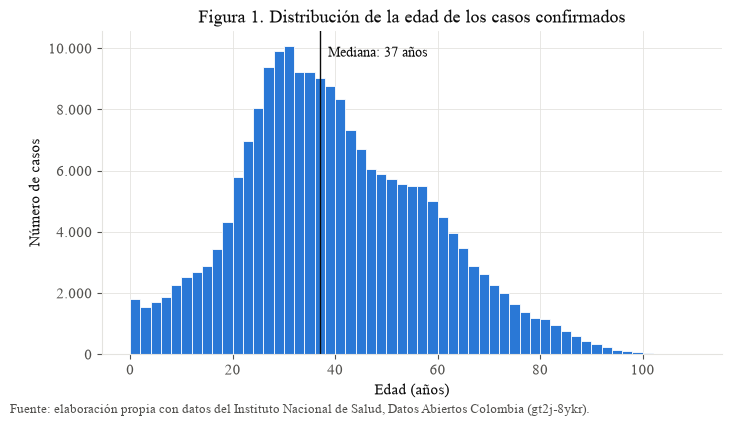

Figura guardada en: figuras/fig01_distribucion_edad.png


In [23]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(casos['edad_anios'], bins=range(0, 112, 2), color=AZUL, edgecolor='white', linewidth=0.6)
mediana_edad = casos['edad_anios'].median()
ax.axvline(mediana_edad, color=TEXTO, linewidth=1)
ax.annotate(f'Mediana: {decimal(mediana_edad, 0)} años', xy=(mediana_edad, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords='offset points', color=TEXTO, fontsize=10)
ax.set_title('Figura 1. Distribución de la edad de los casos confirmados')
ax.set_xlabel('Edad (años)')
ax.set_ylabel('Número de casos')
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(miles))
guardar_figura(fig, 'fig01_distribucion_edad.png')

**Figura 1.** La mitad central de los casos tiene entre 27 y 52 años (primer y tercer cuartil de la tabla anterior) y la mediana es de 37 años. Los menores de 18 años son el 10,18 % de los casos y las personas de 60 años o más el 15,08 %. La distribución es casi simétrica (asimetría de 0,35), con una cola corta hacia las edades altas.

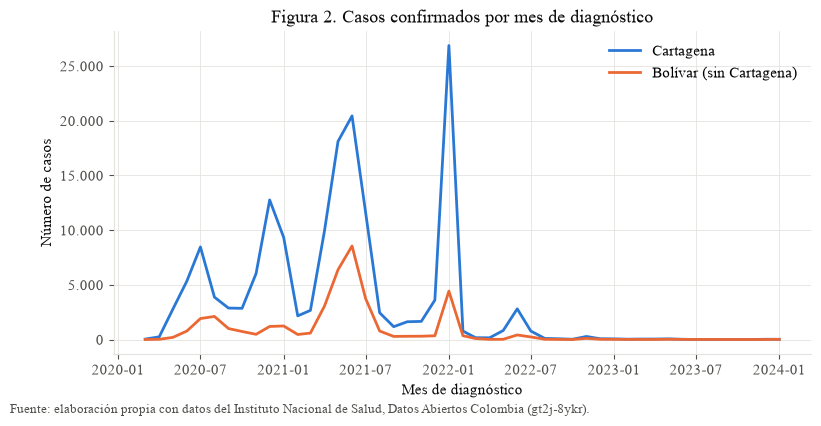

Figura guardada en: figuras/fig02_casos_por_mes.png
Meses con más casos (ambas entidades):
fecha_diagnostico
2022-01    31297
2021-06    28990
2021-05    24483


In [24]:
por_mes = casos.set_index('fecha_diagnostico').groupby(['departamento_nom', pd.Grouper(freq='MS')]).size().unstack(0).fillna(0)
fig, ax = plt.subplots(figsize=(9, 4.2))
for entidad, color in [('Cartagena', AZUL), ('Bolivar', NARANJA)]:
    ax.plot(por_mes.index, por_mes[entidad], color=color, linewidth=2, label=entidad.replace('Bolivar', 'Bolívar (sin Cartagena)'))
ax.set_title('Figura 2. Casos confirmados por mes de diagnóstico')
ax.set_xlabel('Mes de diagnóstico')
ax.set_ylabel('Número de casos')
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(miles))
ax.legend(loc='upper right')
guardar_figura(fig, 'fig02_casos_por_mes.png')
top = por_mes.sum(axis=1).sort_values(ascending=False).head(3)
print('Meses con más casos (ambas entidades):')
print(top.astype(int).rename(lambda d: d.strftime('%Y-%m')).to_string())

**Figura 2.** Los casos llegaron en olas. Los tres meses con más diagnósticos fueron enero de 2022 (31.297 casos), junio de 2021 (28.990) y mayo de 2021 (24.483). Cartagena y el resto de Bolívar siguen el mismo patrón temporal, aunque el pico de enero de 2022 fue mucho más marcado en Cartagena. Desde mediados de 2022 los casos registrados son muy pocos; con estos datos no podemos distinguir una baja real de contagios de una baja en la realización de pruebas.

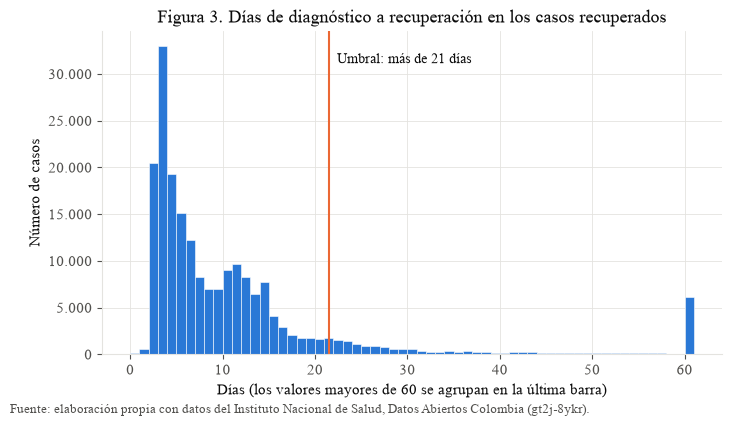

Figura guardada en: figuras/fig03_dias_recuperacion.png
Casos con más de 60 días: 6052
Valores más frecuentes (días: casos): {3.0: 32952, 2.0: 20421, 4.0: 19283, 5.0: 15159, 6.0: 12206}


In [25]:
dias = poblacion['dias_diagnostico_a_recuperacion']
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(dias.clip(upper=60), bins=range(0, 62, 1), color=AZUL, edgecolor='white', linewidth=0.4)
ax.axvline(21.5, color=NARANJA, linewidth=1.5)
ax.annotate('Umbral: más de 21 días', xy=(21.5, ax.get_ylim()[1] * 0.9), xytext=(6, 0),
            textcoords='offset points', color=TEXTO, fontsize=10)
ax.set_title('Figura 3. Días de diagnóstico a recuperación en los casos recuperados')
ax.set_xlabel('Días (los valores mayores de 60 se agrupan en la última barra)')
ax.set_ylabel('Número de casos')
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(miles))
guardar_figura(fig, 'fig03_dias_recuperacion.png')
print('Casos con más de 60 días:', int((dias > 60).sum()))
print('Valores más frecuentes (días: casos):', dias.value_counts().head(5).to_dict())

**Figura 3.** La mayoría de los casos se recuperó en pocos días: el valor más frecuente es de 3 días (32.952 casos). Se ve un segundo grupo de casos entre los 10 y los 15 días y una cola larga hacia la derecha, con 6.052 casos de más de 60 días. La línea naranja marca el umbral de la variable objetivo: lo que queda a su derecha es la recuperación prolongada.

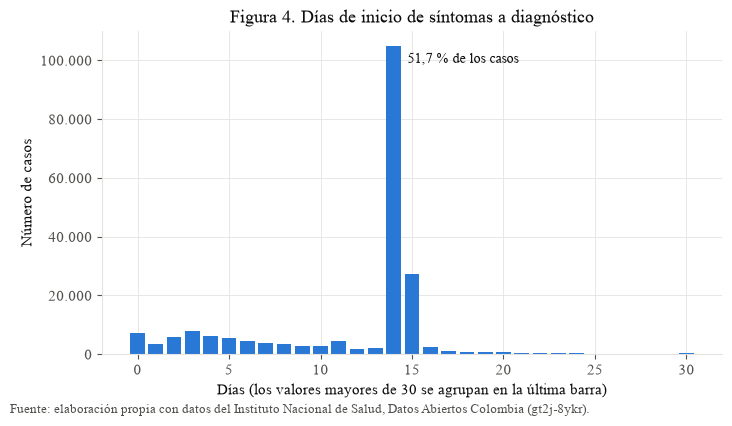

Figura guardada en: figuras/fig04_dias_sintomas_diagnostico.png
Porcentaje con 14 días: 51.65 | con 15 días: 13.4


In [26]:
sint = casos['dias_sintomas_a_diagnostico'].dropna()
fig, ax = plt.subplots(figsize=(8, 4.2))
conteo_sint = sint.clip(upper=30).value_counts().sort_index()
ax.bar(conteo_sint.index, conteo_sint.values, color=AZUL, width=0.8)
ax.set_title('Figura 4. Días de inicio de síntomas a diagnóstico')
ax.set_xlabel('Días (los valores mayores de 30 se agrupan en la última barra)')
ax.set_ylabel('Número de casos')
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(miles))
pico = conteo_sint.idxmax()
ax.annotate(f'{decimal(conteo_sint.max() / len(sint) * 100)} % de los casos', xy=(pico, conteo_sint.max()),
            xytext=(10, -12), textcoords='offset points', color=TEXTO, fontsize=10)
guardar_figura(fig, 'fig04_dias_sintomas_diagnostico.png')
print('Porcentaje con 14 días:', round((sint == 14).mean() * 100, 2), '| con 15 días:', round((sint == 15).mean() * 100, 2))

**Figura 4.** Esta figura muestra un problema de calidad. El 51,65 % de los casos con dato tiene exactamente 14 días entre el inicio de síntomas y el diagnóstico, y el 13,4 % tiene 15. Una distribución real de tiempos no se amontona así en un solo valor, por lo que los resultados sugieren que la fuente usa 14 días como valor por defecto. Esta variable debe interpretarse con cuidado en el modelo supervisado.

### 7.3 Comparaciones de la recuperación prolongada

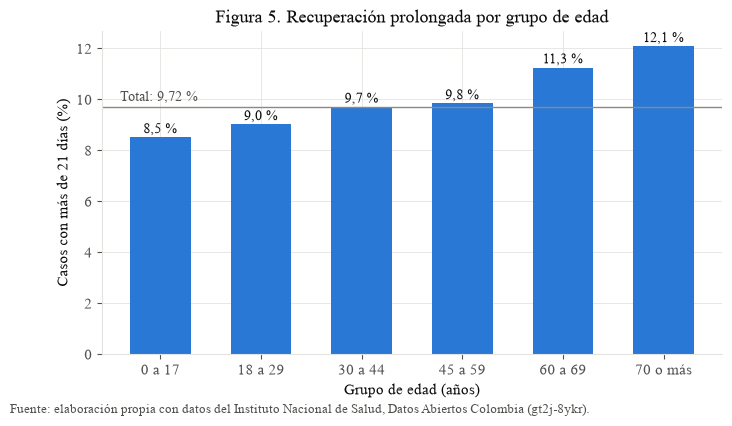

Figura guardada en: figuras/fig05_prolongada_por_edad.png


,casos,pct_prolongada
grupo_edad,,
0 a 17,20677,8.51
18 a 29,44293,9.02
30 a 44,64900,9.71
45 a 59,41704,9.84
60 a 69,16565,11.25
70 o más,11135,12.09


In [27]:
por_edad = poblacion.groupby('grupo_edad', observed=True)['recuperacion_prolongada'].agg(
    casos='size', pct_prolongada=lambda s: s.astype(float).mean() * 100)
tasa_global = poblacion['recuperacion_prolongada'].astype(float).mean() * 100
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(por_edad.index.astype(str), por_edad['pct_prolongada'], color=AZUL, width=0.6)
ax.axhline(tasa_global, color=GRIS, linewidth=1)
ax.annotate(f'Total: {decimal(tasa_global, 2)} %', xy=(-0.4, tasa_global), xytext=(0, 4),
            textcoords='offset points', color=TEXTO_SEC, fontsize=10)
for x, valor in enumerate(por_edad['pct_prolongada']):
    ax.annotate(f'{decimal(valor)} %', xy=(x, valor), xytext=(0, 3), textcoords='offset points',
                ha='center', fontsize=10, color=TEXTO)
ax.set_title('Figura 5. Recuperación prolongada por grupo de edad')
ax.set_xlabel('Grupo de edad (años)')
ax.set_ylabel('Casos con más de 21 días (%)')
guardar_figura(fig, 'fig05_prolongada_por_edad.png')
display(por_edad.round(2))

**Figura 5.** La recuperación prolongada aumenta con la edad: pasa del 8,51 % en menores de 18 años al 11,25 % entre 60 y 69 años y al 12,09 % en las personas de 70 años o más. La diferencia entre los extremos es de unos 3,6 puntos porcentuales. Es un patrón consistente pero moderado: la edad sola no separa bien a los casos prolongados.

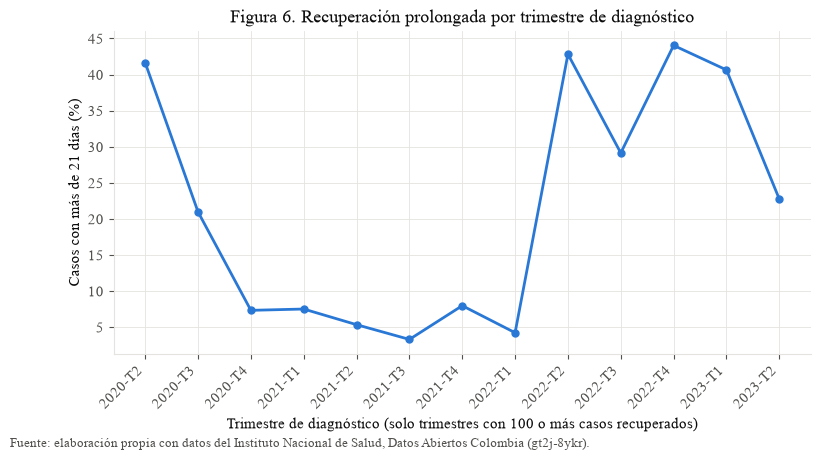

Figura guardada en: figuras/fig06_prolongada_por_trimestre.png


,casos,pct_prolongada
2020-T1,40,32.5
2020-T2,8845,41.64
2020-T3,19789,20.97
2020-T4,23612,7.34
2021-T1,16110,7.52
2021-T2,64922,5.35
2021-T3,19724,3.31
2021-T4,7732,7.98
2022-T1,32255,4.24
2022-T2,4194,42.82


In [28]:
trimestral = poblacion.assign(trimestre=poblacion['fecha_diagnostico'].dt.to_period('Q')).groupby('trimestre').agg(
    casos=('recuperacion_prolongada', 'size'),
    pct_prolongada=('recuperacion_prolongada', lambda s: s.astype(float).mean() * 100))
MIN_CASOS_TRIMESTRE = 100
mostrar = trimestral[trimestral['casos'] >= MIN_CASOS_TRIMESTRE]
fig, ax = plt.subplots(figsize=(9, 4.2))
etiquetas_trim = [f'{p.year}-T{p.quarter}' for p in mostrar.index]
ax.plot(etiquetas_trim, mostrar['pct_prolongada'], color=AZUL, linewidth=2, marker='o', markersize=5)
ax.set_title('Figura 6. Recuperación prolongada por trimestre de diagnóstico')
ax.set_xlabel(f'Trimestre de diagnóstico (solo trimestres con {MIN_CASOS_TRIMESTRE} o más casos recuperados)')
ax.set_ylabel('Casos con más de 21 días (%)')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
guardar_figura(fig, 'fig06_prolongada_por_trimestre.png')
trimestral.index = [f'{p.year}-T{p.quarter}' for p in trimestral.index]
display(trimestral.round(2))

**Figura 6.** El porcentaje de recuperación prolongada cambia mucho según el momento del diagnóstico. Fue alto al comienzo de la pandemia (41,64 % en el segundo trimestre de 2020), se mantuvo entre el 3,31 % y el 7,98 % desde el cuarto trimestre de 2020 hasta el primero de 2022, y volvió a subir a partir del segundo trimestre de 2022 (42,82 %), cuando los casos ya eran muy pocos. Variaciones tan grandes en poco tiempo sugieren que el periodo refleja cambios en la forma de registrar y cerrar los casos, y no solo en la enfermedad.

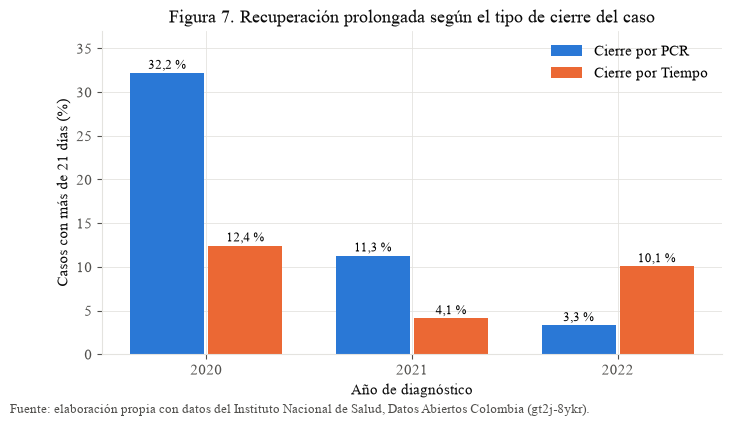

Figura guardada en: figuras/fig07_prolongada_por_cierre.png


,anio_diagnostico,tipo_recuperacion,casos,pct_prolongada
0,2020,PCR,15576,32.18
1,2020,Tiempo,36710,12.44
2,2021,PCR,20849,11.29
3,2021,Tiempo,87639,4.11
4,2022,PCR,1632,3.31
5,2022,Tiempo,36489,10.06


,casos,pct_prolongada
tipo_recuperacion,,
PCR,38059,19.5
Tiempo,161215,7.41


In [29]:
cierre = poblacion.dropna(subset=['tipo_recuperacion']).groupby(['anio_diagnostico', 'tipo_recuperacion'])['recuperacion_prolongada'].agg(
    casos='size', pct_prolongada=lambda s: s.astype(float).mean() * 100).reset_index()
cierre = cierre[cierre['anio_diagnostico'] <= 2022]  # 2023 y 2024 tienen muy pocos casos
anios = sorted(cierre['anio_diagnostico'].unique())
ancho = 0.36
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, (tipo, color) in enumerate([('PCR', AZUL), ('Tiempo', NARANJA)]):
    datos = cierre[cierre['tipo_recuperacion'] == tipo].set_index('anio_diagnostico').reindex(anios)
    xs = np.arange(len(anios)) + (i - 0.5) * (ancho + 0.02)
    ax.bar(xs, datos['pct_prolongada'], width=ancho, color=color, label=f'Cierre por {tipo}')
    for x, valor in zip(xs, datos['pct_prolongada']):
        ax.annotate(f'{decimal(valor)} %', xy=(x, valor), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9)
ax.set_xticks(np.arange(len(anios)), [str(a) for a in anios])
ax.set_title('Figura 7. Recuperación prolongada según el tipo de cierre del caso')
ax.set_xlabel('Año de diagnóstico')
ax.set_ylabel('Casos con más de 21 días (%)')
ax.set_ylim(0, cierre['pct_prolongada'].max() * 1.15)
ax.legend(loc='upper right')
guardar_figura(fig, 'fig07_prolongada_por_cierre.png')
display(cierre.round(2))
global_cierre = poblacion.groupby('tipo_recuperacion')['recuperacion_prolongada'].agg(
    casos='size', pct_prolongada=lambda s: round(s.astype(float).mean() * 100, 2))
display(global_cierre)

**Figura 7.** El tipo de cierre del caso cambia la duración registrada. En 2020, los casos cerrados por PCR tuvieron recuperación prolongada en el 32,18 % de las veces, frente al 12,44 % de los cerrados por tiempo; en 2021 la relación fue de 11,29 % frente a 4,11 %, y en 2022 se invirtió (3,31 % frente a 10,06 %). En toda la población, el cierre por PCR fue prolongado en el 19,5 % de los casos y el cierre por tiempo en el 7,41 %. Esto confirma un sesgo de medición en la variable objetivo. No usaremos el tipo de cierre como predictor porque solo se conoce al cerrar el caso, pero su efecto queda mezclado con el periodo del diagnóstico.

In [30]:
comparacion = []
for nombre, col in [('Entidad', 'departamento_nom'), ('Sexo', 'sexo'), ('Tipo de contagio', 'fuente_tipo_contagio'),
                    ('Pertenencia étnica', 'pertenencia_etnica_cod'), ('Asintomático', 'asintomatico')]:
    tabla = poblacion.groupby(col)['recuperacion_prolongada'].agg(
        casos='size', pct_prolongada=lambda s: round(s.astype(float).mean() * 100, 2))
    for categoria, fila in tabla.iterrows():
        etiqueta = ETNIAS.get(categoria, categoria) if col == 'pertenencia_etnica_cod' else categoria
        comparacion.append((nombre, etiqueta, int(fila['casos']), fila['pct_prolongada']))
display(pd.DataFrame(comparacion, columns=['variable', 'categoría', 'casos', 'pct_prolongada']))

,variable,categoría,casos,pct_prolongada
0,Entidad,Bolivar,39057,9.30
1,Entidad,Cartagena,160217,9.82
2,Sexo,F,106756,9.14
3,Sexo,M,92518,10.40
4,Tipo de contagio,Comunitaria,161606,10.49
5,Tipo de contagio,Importado,41,19.51
6,Tipo de contagio,Relacionado,37627,6.40
7,Pertenencia étnica,Indígena,1930,18.60
8,Pertenencia étnica,ROM,1,0.00
9,Pertenencia étnica,Negro,25212,9.37


**Otras comparaciones.** La recuperación prolongada fue algo mayor en Cartagena (9,82 %) que en el resto de Bolívar (9,30 %) y en hombres (10,40 %) que en mujeres (9,14 %). Fue menor en los contagios relacionados (6,40 %) que en los comunitarios (10,49 %). En la población indígena llegó al 18,60 %, frente al 9,37 % en la población negra y al 9,67 % en "Otro"; como son solo 1.930 casos indígenas, la diferencia debe tomarse con cautela. Los casos asintomáticos tuvieron recuperación prolongada en el 51,87 % de las veces, pero son apenas 669 casos y su fecha de inicio de síntomas está vacía por definición. Los 41 casos importados (19,51 %) son demasiado pocos para sacar conclusiones.

### 7.4 Relaciones entre variables

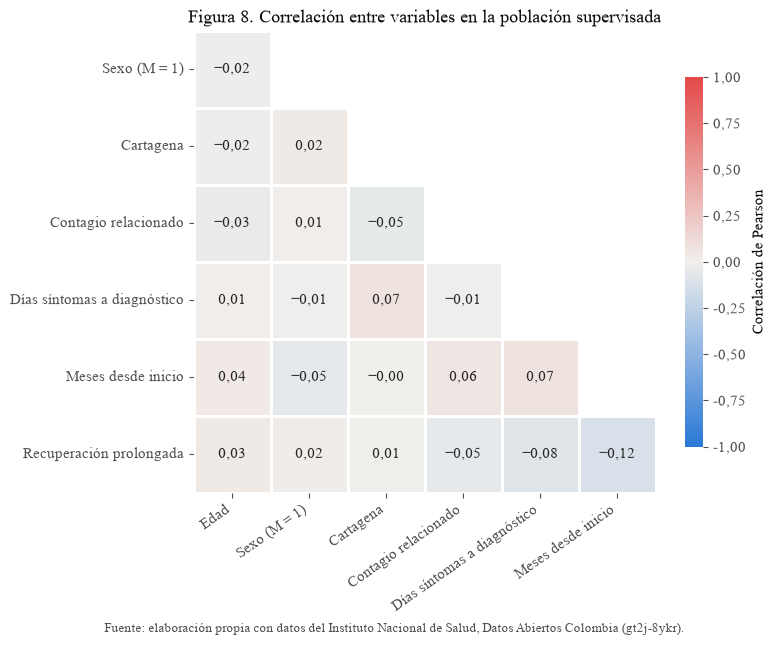

Figura guardada en: figuras/fig08_correlaciones.png
Correlación de cada variable con la recuperación prolongada:
Meses desde inicio            -0.118
Días síntomas a diagnóstico   -0.084
Contagio relacionado          -0.054
Cartagena                      0.007
Sexo (M = 1)                   0.021
Edad                           0.026


In [31]:
VARS_CORR = {'edad_anios': 'Edad', 'sexo_cod': 'Sexo (M = 1)', 'es_cartagena': 'Cartagena',
             'contagio_relacionado': 'Contagio relacionado', 'dias_sintomas_a_diagnostico': 'Días síntomas a diagnóstico',
             'meses_desde_inicio': 'Meses desde inicio', 'recuperacion_prolongada': 'Recuperación prolongada'}
datos_corr = poblacion[list(VARS_CORR)].astype(float).rename(columns=VARS_CORR)
corr = datos_corr.corr(method='pearson')
divergente = LinearSegmentedColormap.from_list('azul_gris_rojo', ['#2a78d6', '#f0efec', '#e34948'])
fig, ax = plt.subplots(figsize=(7.5, 6))
triangulo = corr.iloc[1:, :-1]
mascara = np.triu(np.ones_like(triangulo, dtype=bool), k=1)
anotaciones = triangulo.map(lambda v: decimal(v, 2).replace('-', '−'))
sns.heatmap(triangulo, mask=mascara, vmin=-1, vmax=1, cmap=divergente, annot=anotaciones, fmt='', square=True,
            linewidths=2, linecolor='white', cbar_kws={'label': 'Correlación de Pearson', 'shrink': 0.8}, ax=ax)
ax.set_title('Figura 8. Correlación entre variables en la población supervisada')
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: decimal(v, 2)))
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
guardar_figura(fig, 'fig08_correlaciones.png')
print('Correlación de cada variable con la recuperación prolongada:')
print(corr['Recuperación prolongada'].drop('Recuperación prolongada').sort_values().round(3).to_string())

**Figura 8.** La correlación de Pearson mide la relación lineal entre dos variables con un valor entre −1 y 1; cero indica que no hay relación lineal. Todas las correlaciones con la recuperación prolongada son débiles. La más fuerte es la de los meses desde el inicio de la pandemia (−0,118), seguida por los días de síntomas a diagnóstico (−0,084) y el contagio relacionado (−0,054); la edad, el sexo y Cartagena están por debajo de 0,03 en valor absoluto. Las predictoras tampoco están correlacionadas entre sí, así que no hay información repetida. Estos valores anticipan que un modelo sencillo tendrá un poder de predicción limitado.

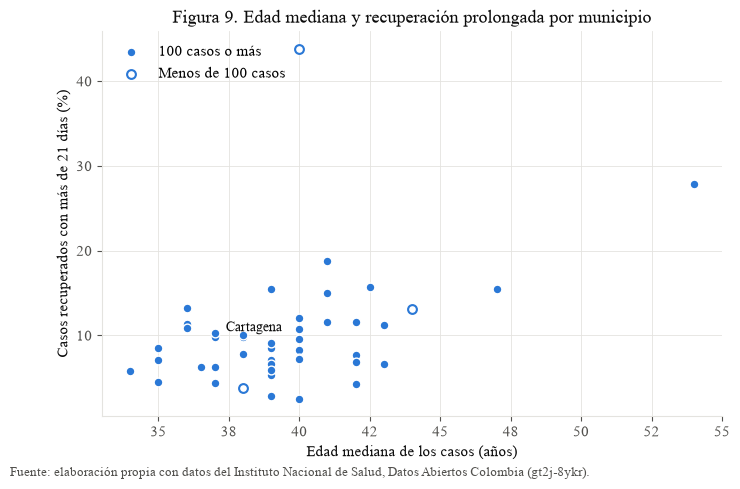

Figura guardada en: figuras/fig09_municipios_edad_prolongada.png
Correlación de Pearson entre ambas variables (46 municipios): 0.418
Rango del porcentaje de recuperación prolongada por municipio: 2.54 a 43.84


,municipio_nom,casos,edad_mediana,pct_recuperacion_prolongada
45,San Jacinto Del Cauca,80,40.0,43.84
40,Morales,123,54.0,27.88
20,Achi,443,41.0,18.74
33,Arenal,212,42.5,15.66
30,San Martin De Loba,229,47.0,15.49


In [32]:
fig, ax = plt.subplots(figsize=(8, 5))
estables = municipios[~municipios['menos_de_100_casos']]
pocos = municipios[municipios['menos_de_100_casos']]
ax.scatter(estables['edad_mediana'], estables['pct_recuperacion_prolongada'], s=40, color=AZUL,
           edgecolor='white', linewidth=1, label='100 casos o más')
ax.scatter(pocos['edad_mediana'], pocos['pct_recuperacion_prolongada'], s=40, facecolor='white',
           edgecolor=AZUL, linewidth=1.5, label='Menos de 100 casos')
ctg = municipios[municipios['departamento_nom'] == 'Cartagena'].iloc[0]
ax.annotate('Cartagena', xy=(ctg['edad_mediana'], ctg['pct_recuperacion_prolongada']), xytext=(8, 4),
            textcoords='offset points', fontsize=10, color=TEXTO)
ax.set_title('Figura 9. Edad mediana y recuperación prolongada por municipio')
ax.set_xlabel('Edad mediana de los casos (años)')
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: decimal(v, 0)))
ax.set_ylabel('Casos recuperados con más de 21 días (%)')
ax.legend(loc='upper left')
guardar_figura(fig, 'fig09_municipios_edad_prolongada.png')
print('Correlación de Pearson entre ambas variables (46 municipios):',
      round(municipios['edad_mediana'].corr(municipios['pct_recuperacion_prolongada']), 3))
print('Rango del porcentaje de recuperación prolongada por municipio:',
      municipios['pct_recuperacion_prolongada'].min(), 'a', municipios['pct_recuperacion_prolongada'].max())
display(municipios[['municipio_nom', 'casos', 'edad_mediana', 'pct_recuperacion_prolongada']]
        .sort_values('pct_recuperacion_prolongada', ascending=False).head(5).round(2))

**Figura 9.** Cada punto es un municipio. Los municipios con casos de mayor edad mediana tienden a tener más recuperación prolongada: la correlación entre ambas variables es de 0,418 en los 46 municipios. El porcentaje de recuperación prolongada va del 2,54 % al 43,84 %. El valor más alto es de San Jacinto Del Cauca, con solo 80 casos, por lo que no es estable. Morales (123 casos) combina la edad mediana más alta (54 años) con el 27,88 % de recuperación prolongada. Cartagena queda en la zona media. Esta dispersión entre municipios es la que estudiaremos con el agrupamiento.

### 7.5 Discusión de calidad, sesgos y limitaciones

El análisis exploratorio deja cuatro ideas para las siguientes fases:

1. **La variable objetivo depende del registro.** La duración de la recuperación cambia con el tipo de cierre (figura 7) y con el periodo (figura 6). Por eso, cualquier modelo que use el periodo puede estar aprendiendo cómo se cerraban los casos y no solo cómo evolucionaban las personas.
2. **Las señales individuales son débiles.** La edad muestra un gradiente consistente pero moderado (figura 5) y las correlaciones lineales son bajas (figura 8). Esperamos un modelo supervisado útil para priorizar grupos, no para predecir casos individuales.
3. **Hay variables con problemas de medición.** Los días de síntomas a diagnóstico están amontonados en 14 (figura 4) y la pertenencia étnica depende del autorreconocimiento. Sus resultados deben leerse con prudencia.
4. **El territorio aporta variación.** Los municipios difieren en edad mediana y en recuperación prolongada (figura 9), pero tres de ellos tienen menos de 100 casos y Cartagena concentra el 80,21 % de los datos.

Estas limitaciones no impiden el análisis, pero acotan lo que se puede concluir: los resultados sugieren asociaciones territoriales y poblacionales, no causas ni diagnósticos individuales.

## 8. Modelado supervisado

El tutor aprobó la ficha de trazabilidad antes de iniciar esta sección, como exige la guía. Aquí entrenamos un modelo de clasificación para la variable objetivo aprobada, `recuperacion_prolongada`. Según la regla de pertinencia de la guía, como la variable objetivo representa dos categorías (prolongada o no prolongada), el problema es de **clasificación** y no de regresión.

### 8.1 Variable objetivo y población

La población son los casos recuperados con días de recuperación calculables (sección 6.8). La clase positiva, la que queremos detectar, es la recuperación prolongada.

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

pob = casos[casos['en_poblacion_supervisada']].copy()
y = pob['recuperacion_prolongada'].astype(int)
print('Casos en la población supervisada:', len(pob))
print('Recuperación prolongada (1):', int(y.sum()), f'({y.mean() * 100:.2f} %)')
print('No prolongada (0):', int((y == 0).sum()), f'({(1 - y.mean()) * 100:.2f} %)')
print('Razón entre clases (no prolongada por cada prolongada):', round((y == 0).sum() / y.sum(), 2))

Casos en la población supervisada: 199274
Recuperación prolongada (1): 19372 (9.72 %)
No prolongada (0): 179902 (90.28 %)
Razón entre clases (no prolongada por cada prolongada): 9.29


De los 199.274 casos, 19.372 (9,72 %) tuvieron recuperación prolongada y 179.902 (90,28 %) no. Hay 9,29 casos no prolongados por cada prolongado. Este **desbalance de clases** significa que un modelo que siempre diga "no prolongada" acertaría cerca del 90 % de las veces sin servir para nada. Por eso no evaluaremos solo con la exactitud.

### 8.2 Variables predictoras y variables excluidas

Para cada columna nos preguntamos si ya se conoce el día del diagnóstico. Si solo se conoce después, usarla sería **fuga de información**: el modelo aprendería de datos que no tendría en la práctica y sus métricas se inflarían. También excluimos las columnas redundantes, que repiten información de otra predictora.

In [34]:
PRED_NUMERICAS = ['edad_anios', 'dias_sintomas_a_diagnostico', 'meses_desde_inicio']
PRED_BINARIAS = ['sexo_cod', 'es_cartagena', 'contagio_importado', 'contagio_relacionado', 'asintomatico']
PRED_CATEGORICAS = ['pertenencia_etnica_cod']
PREDICTORAS = PRED_NUMERICAS + PRED_BINARIAS + PRED_CATEGORICAS

EXCLUIDAS = pd.DataFrame([
    ('estado, ubicacion', 'Fuga de información', 'Describen la situación del caso al cerrarse, no el día del diagnóstico'),
    ('recuperado, fecha_recuperado, fecha_muerte', 'Fuga de información', 'Solo se conocen al final del caso'),
    ('dias_diagnostico_a_recuperacion', 'Fuga de información', 'Define la variable objetivo'),
    ('tipo_recuperacion', 'Fuga de información', 'Se conoce al cerrar el caso y cambia la duración registrada (figura 7)'),
    ('alerta_muerte_antes_diagnostico', 'Fuga de información', 'Usa la fecha de muerte'),
    ('fecha_inicio_sintomas, fecha_diagnostico', 'Redundante', 'Su información entra como días de síntomas a diagnóstico y meses desde el inicio'),
    ('anio_diagnostico', 'Redundante', 'Está contenido en meses_desde_inicio'),
    ('edad, unidad_medida, grupo_edad, edad_atipica_iqr', 'Redundante', 'Su información entra como edad_anios'),
    ('departamento_*, municipio_*', 'Redundante o muy detallada', 'Se usa es_cartagena; el municipio se estudia en el agrupamiento'),
    ('sexo, fuente_tipo_contagio', 'Redundante', 'Entran codificadas como sexo_cod y contagio_*'),
    ('etnia_imputada, alerta_notificacion_posterior_reporte', 'Sin valor predictivo', 'Banderas de calidad, no características del caso'),
], columns=['variables', 'motivo', 'explicación'])
display(EXCLUIDAS)

X = pob[PREDICTORAS].copy()
X['asintomatico'] = X['asintomatico'].astype(int)
print('Predictoras:', PREDICTORAS)
print('Dimensión de X:', X.shape)
print('Valores faltantes por predictora:', X.isna().sum()[X.isna().sum() > 0].to_dict())
print('De los faltantes en días de síntomas a diagnóstico, cuántos son asintomáticos:',
      int((X['dias_sintomas_a_diagnostico'].isna() & X['asintomatico'].eq(1)).sum()))

,variables,motivo,explicación
0,"estado, ubicacion",Fuga de información,"Describen la situación del caso al cerrarse, n..."
1,"recuperado, fecha_recuperado, fecha_muerte",Fuga de información,Solo se conocen al final del caso
2,dias_diagnostico_a_recuperacion,Fuga de información,Define la variable objetivo
3,tipo_recuperacion,Fuga de información,Se conoce al cerrar el caso y cambia la duraci...
4,alerta_muerte_antes_diagnostico,Fuga de información,Usa la fecha de muerte
5,"fecha_inicio_sintomas, fecha_diagnostico",Redundante,Su información entra como días de síntomas a d...
6,anio_diagnostico,Redundante,Está contenido en meses_desde_inicio
7,"edad, unidad_medida, grupo_edad, edad_atipica_iqr",Redundante,Su información entra como edad_anios
8,"departamento_*, municipio_*",Redundante o muy detallada,Se usa es_cartagena; el municipio se estudia e...
9,"sexo, fuente_tipo_contagio",Redundante,Entran codificadas como sexo_cod y contagio_*


Predictoras: ['edad_anios', 'dias_sintomas_a_diagnostico', 'meses_desde_inicio', 'sexo_cod', 'es_cartagena', 'contagio_importado', 'contagio_relacionado', 'asintomatico', 'pertenencia_etnica_cod']
Dimensión de X: (199274, 9)
Valores faltantes por predictora: {'dias_sintomas_a_diagnostico': 669}
De los faltantes en días de síntomas a diagnóstico, cuántos son asintomáticos: 669


Conservamos 9 predictoras conocidas el día del diagnóstico: edad en años, días de síntomas a diagnóstico, meses desde el inicio de la pandemia, sexo, si el caso es de Cartagena, los dos indicadores de tipo de contagio (con Comunitaria como referencia), si el caso es asintomático y la pertenencia étnica. La única predictora con faltantes es `dias_sintomas_a_diagnostico`, con 669 casos, y los 669 son exactamente los asintomáticos, que no tienen fecha de inicio de síntomas. Como la variable `asintomatico` ya guarda esa información, esos faltantes se pueden imputar sin perderla.

Dos predictoras requieren cautela por lo visto en el análisis exploratorio. `meses_desde_inicio` se conoce el día del diagnóstico, así que no es fuga, pero también refleja cómo se registraban y cerraban los casos en cada periodo (figuras 6 y 7). Y `dias_sintomas_a_diagnostico` está amontonada en 14 días (figura 4).

### 8.3 División en entrenamiento y prueba

Separamos el 80 % de los casos para entrenar y el 20 % para probar. El modelo nunca ve los datos de prueba durante el entrenamiento, así que las métricas sobre ellos indican cómo se comportaría con casos nuevos. Usamos una división **estratificada**, que mantiene la misma proporción de casos prolongados en ambos conjuntos, y una semilla fija para que la división sea siempre la misma.

In [35]:
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
division = pd.DataFrame({
    'casos': [len(y_ent), len(y_pru)],
    'prolongados': [int(y_ent.sum()), int(y_pru.sum())],
    'pct_prolongados': [round(y_ent.mean() * 100, 2), round(y_pru.mean() * 100, 2)],
}, index=['entrenamiento', 'prueba'])
display(division)

,casos,prolongados,pct_prolongados
entrenamiento,159419,15498,9.72
prueba,39855,3874,9.72


El conjunto de entrenamiento tiene 159.419 casos (15.498 prolongados) y el de prueba 39.855 (3.874 prolongados). Ambos tienen 9,72 % de casos prolongados, igual que la población completa.

### 8.4 Línea base

La línea base es un modelo trivial que siempre predice la clase más frecuente. Cualquier modelo útil debe superarla. Para evaluar usamos estas métricas sobre el conjunto de prueba:

- **Accuracy (exactitud):** proporción de casos bien clasificados.
- **Precision (precisión):** de los casos que el modelo marca como prolongados, cuántos lo son.
- **Recall (sensibilidad):** de los casos realmente prolongados, cuántos detecta el modelo.
- **F1:** promedio armónico de precisión y sensibilidad; solo es alto si ambas lo son.
- **ROC-AUC:** probabilidad de que el modelo asigne más riesgo a un caso prolongado que a uno no prolongado elegido al azar; 0,5 equivale al azar y 1 a una separación perfecta.
- **Matriz de confusión:** verdaderos positivos (VP), falsos positivos (FP), falsos negativos (FN) y verdaderos negativos (VN).

In [36]:
def evaluar(modelo, nombre, X_eval=None, y_eval=None):
    """Métricas de clasificación en el conjunto de prueba. La clase positiva es la recuperación prolongada."""
    X_eval = X_pru if X_eval is None else X_eval
    y_eval = y_pru if y_eval is None else y_eval
    pred = modelo.predict(X_eval)
    prob = modelo.predict_proba(X_eval)[:, 1]
    vn, fp, fn, vp = confusion_matrix(y_eval, pred, labels=[0, 1]).ravel()
    return {'modelo': nombre,
            'accuracy': accuracy_score(y_eval, pred),
            'precision': precision_score(y_eval, pred, zero_division=0),
            'recall': recall_score(y_eval, pred, zero_division=0),
            'f1': f1_score(y_eval, pred, zero_division=0),
            'roc_auc': roc_auc_score(y_eval, prob),
            'VP': vp, 'FP': fp, 'FN': fn, 'VN': vn}

linea_base = DummyClassifier(strategy='most_frequent').fit(X_ent, y_ent)
resultados = [evaluar(linea_base, 'Línea base (clase más frecuente)')]
display(pd.DataFrame(resultados).set_index('modelo').round(3))

,accuracy,precision,recall,f1,roc_auc,VP,FP,FN,VN
modelo,,,,,,,,,
Línea base (clase más frecuente),0.903,0.0,0.0,0.0,0.5,0,0,3874,35981


La línea base tiene una exactitud de 0,903 porque acierta todos los casos no prolongados, pero su sensibilidad, precisión y F1 son 0: no detecta ninguno de los 3.874 casos prolongados de la prueba. Su ROC-AUC de 0,5 equivale al azar. Esta es la referencia que deben superar los modelos.

### 8.5 Preparación dentro del modelo

Toda la preparación se hace dentro de un *pipeline*, una cadena de pasos que se ajusta solo con los datos de entrenamiento y luego se aplica igual a los de prueba. Así ninguna información de la prueba influye en el modelo. Los pasos son: imputar con la mediana los días de síntomas a diagnóstico de los asintomáticos (la variable `asintomatico` conserva esa información), escalar las variables numéricas y codificar la pertenencia étnica con variables indicadoras, con "Otro" como categoría de referencia.

Entrenamos cada modelo con dos conjuntos de predictoras: **con periodo**, que incluye `meses_desde_inicio`, y **sin periodo**, que lo excluye. Como el análisis exploratorio mostró que el periodo refleja en buena parte la forma de registrar y cerrar los casos, la comparación nos dice qué parte del desempeño se debe a las características de las personas y qué parte al momento del diagnóstico.

In [37]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import roc_curve

# Categorías étnicas presentes; 6 ('Otro') queda como referencia
CATEGORIAS_ETNIA = sorted(int(c) for c in X['pertenencia_etnica_cod'].unique())
print('Categorías étnicas presentes:', CATEGORIAS_ETNIA, '| referencia: 6 (Otro)')

def preprocesador(numericas, escalar=True):
    """Imputa con la mediana y escala las numéricas, deja las binarias y codifica la etnia en one-hot.
    El árbol no necesita escalamiento, así que para él se omite y sus reglas quedan en unidades reales."""
    pasos = [('imputar', SimpleImputer(strategy='median'))] + ([('escalar', StandardScaler())] if escalar else [])
    return ColumnTransformer([
        ('numericas', Pipeline(pasos), numericas),
        ('binarias', 'passthrough', PRED_BINARIAS),
        ('etnia', OneHotEncoder(categories=[CATEGORIAS_ETNIA], drop=[6]), PRED_CATEGORICAS),
    ])

CONJUNTOS = {
    'con periodo': PREDICTORAS,
    'sin periodo': [c for c in PREDICTORAS if c != 'meses_desde_inicio'],
}
NUMERICAS_POR_CONJUNTO = {nombre: [c for c in PRED_NUMERICAS if c in cols] for nombre, cols in CONJUNTOS.items()}
for nombre, cols in CONJUNTOS.items():
    print(f'{nombre}: {len(cols)} predictoras')

Categorías étnicas presentes: [1, 2, 5, 6] | referencia: 6 (Otro)
con periodo: 9 predictoras
sin periodo: 8 predictoras


### 8.6 Modelo 1: regresión logística

La regresión logística estima la probabilidad de que un caso sea prolongado como una combinación de las predictoras. Es un modelo sencillo e interpretable: cada coeficiente indica si una variable aumenta o disminuye esa probabilidad. Usamos `class_weight='balanced'`, que da más peso a los casos prolongados durante el entrenamiento para compensar que son solo el 9,72 %.

In [38]:
modelos = {}
for conjunto, cols in CONJUNTOS.items():
    modelo = Pipeline([
        ('prep', preprocesador(NUMERICAS_POR_CONJUNTO[conjunto])),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000)),
    ]).fit(X_ent[cols], y_ent)
    modelos[('Regresión logística', conjunto)] = (modelo, cols)
    print(f'Regresión logística {conjunto}: entrenada con {len(cols)} predictoras')

Regresión logística con periodo: entrenada con 9 predictoras
Regresión logística sin periodo: entrenada con 8 predictoras


### 8.7 Modelo 2: árbol de decisión

El árbol de decisión divide los casos con preguntas sucesivas sobre las predictoras, por ejemplo "¿el diagnóstico fue antes de agosto de 2020?", y asigna una clase a cada grupo final. Capta relaciones no lineales y se puede leer como un conjunto de reglas. También usamos clases ponderadas. Un árbol muy profundo memoriza los datos de entrenamiento y falla con casos nuevos, lo que se llama **sobreajuste**; por eso elegimos la profundidad máxima entre 3 y 8 con **validación cruzada** de 5 pliegues: el entrenamiento se divide en 5 partes, se entrena con 4 y se evalúa con la restante, rotando, y se elige la profundidad con mejor F1 promedio.

In [39]:
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
PROFUNDIDADES = [3, 4, 5, 6, 7, 8]
tablas_cv = []
for conjunto, cols in CONJUNTOS.items():
    busqueda = GridSearchCV(
        Pipeline([('prep', preprocesador(NUMERICAS_POR_CONJUNTO[conjunto], escalar=False)),
                  ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA))]),
        param_grid={'clf__max_depth': PROFUNDIDADES}, scoring='f1', cv=validacion, n_jobs=1,
    ).fit(X_ent[cols], y_ent)
    modelos[('Árbol de decisión', conjunto)] = (busqueda.best_estimator_, cols)
    cv = pd.DataFrame(busqueda.cv_results_)[['param_clf__max_depth', 'mean_test_score', 'std_test_score']]
    cv.columns = ['profundidad', 'f1_medio_validacion', 'desviacion']
    cv.insert(0, 'conjunto', conjunto)
    tablas_cv.append(cv)
    print(f"Árbol {conjunto}: profundidad elegida {busqueda.best_params_['clf__max_depth']}, F1 medio en validación {busqueda.best_score_:.3f}")
display(pd.concat(tablas_cv).round(3).set_index(['conjunto', 'profundidad']))

Árbol con periodo: profundidad elegida 3, F1 medio en validación 0.416


Árbol sin periodo: profundidad elegida 4, F1 medio en validación 0.259


f1_medio_validacion  desviacion
conjunto    profundidad                                 
con periodo 3                          0.416       0.007
            4                          0.371       0.008
            5                          0.404       0.021
            6                          0.391       0.013
            7                          0.408       0.019
            8                          0.402       0.013
sin periodo 3                          0.258       0.003
            4                          0.259       0.003
            5                          0.258       0.009
            6                          0.254       0.003
            7                          0.259       0.004
            8                          0.257       0.004

Con periodo, la validación cruzada eligió una profundidad de 3, con un F1 medio de 0,416 y una desviación de 0,007 entre pliegues. Sin periodo eligió una profundidad de 4, con un F1 medio de 0,259; en ese caso todas las profundidades dan valores entre 0,254 y 0,259, así que hacer el árbol más complejo no aporta. Las desviaciones pequeñas indican que los resultados son estables entre pliegues.

### 8.8 Evaluación en el conjunto de prueba

Comparamos los cuatro modelos con la línea base. Agregamos el *lift*, que divide la precisión del modelo entre la tasa de casos prolongados de la población: un lift de 2 significa que entre los casos marcados por el modelo hay el doble de prolongados que al azar.

In [40]:
for (nombre, conjunto), (modelo, cols) in modelos.items():
    resultados.append(evaluar(modelo, f'{nombre} ({conjunto})', X_pru[cols]))
tabla_metricas = pd.DataFrame(resultados).set_index('modelo')
tasa_base = y_pru.mean()
tabla_metricas['lift'] = tabla_metricas['precision'] / tasa_base
display(tabla_metricas.round(3))
print(f'Tasa de prolongados en la prueba: {tasa_base * 100:.2f} %')
print('El lift indica cuántas veces más frecuentes son los casos prolongados entre los marcados por el modelo que en la población.')

,accuracy,precision,recall,f1,roc_auc,VP,FP,FN,VN,lift
modelo,,,,,,,,,,
Línea base (clase más frecuente),0.903,0.000,0.000,0.000,0.500,0,0,3874,35981,0.000
Regresión logística (con periodo),0.631,0.147,0.580,0.234,0.635,2245,13060,1629,22921,1.509
Regresión logística (sin periodo),0.663,0.146,0.511,0.228,0.616,1980,11538,1894,24443,1.507
Árbol de decisión (con periodo),0.868,0.363,0.479,0.413,0.737,1855,3256,2019,32725,3.734
Árbol de decisión (sin periodo),0.698,0.170,0.544,0.260,0.656,2108,10258,1766,25723,1.754


Tasa de prolongados en la prueba: 9.72 %
El lift indica cuántas veces más frecuentes son los casos prolongados entre los marcados por el modelo que en la población.


Todos los modelos superan a la línea base en sensibilidad, F1 y ROC-AUC. El mejor es el **árbol de decisión con periodo**: F1 de 0,413, ROC-AUC de 0,737, precisión de 0,363 y sensibilidad de 0,479. Detecta 1.855 de los 3.874 casos prolongados de la prueba y, entre los casos que marca, los prolongados son 3,73 veces más frecuentes que en la población. Su exactitud (0,868) es menor que la de la línea base (0,903), lo cual es esperable: la línea base no detecta ningún caso prolongado.

La regresión logística con periodo detecta más casos (sensibilidad de 0,580), pero a costa de 13.060 falsos positivos, por lo que su precisión es de solo 0,147 y su F1 de 0,234.

**Sin el periodo, el desempeño cae.** El F1 del árbol baja de 0,413 a 0,260 y su ROC-AUC de 0,737 a 0,656. En la regresión logística la caída es pequeña (F1 de 0,234 a 0,228; ROC-AUC de 0,635 a 0,616), porque un modelo lineal no capta que la recuperación prolongada fue alta al comienzo y al final del periodo y baja en el medio (figura 6). Los resultados sugieren que la mayor parte de lo que el mejor modelo aprende es el momento del diagnóstico.

**¿Qué error es más grave?** Para la planeación del CRT, un falso negativo significa no anticipar un grupo que necesitaría acompañamiento, y un falso positivo significa dirigir comunicación preventiva a quien no la necesitaba. Como las acciones propuestas son de bajo costo y de carácter preventivo, el falso negativo es el error más grave; aun así, demasiados falsos positivos diluyen el esfuerzo. Por eso el F1, que equilibra ambos, es la métrica principal.

In [41]:
filas = []
for (nombre, conjunto), (modelo, cols) in modelos.items():
    ent = evaluar(modelo, '', X_ent[cols], y_ent)
    pru = evaluar(modelo, '', X_pru[cols], y_pru)
    filas.append({'modelo': f'{nombre} ({conjunto})', 'f1_entrenamiento': ent['f1'], 'f1_prueba': pru['f1'],
                  'roc_auc_entrenamiento': ent['roc_auc'], 'roc_auc_prueba': pru['roc_auc']})
display(pd.DataFrame(filas).set_index('modelo').round(3))

,f1_entrenamiento,f1_prueba,roc_auc_entrenamiento,roc_auc_prueba
modelo,,,,
Regresión logística (con periodo),0.236,0.234,0.637,0.635
Regresión logística (sin periodo),0.228,0.228,0.619,0.616
Árbol de decisión (con periodo),0.416,0.413,0.734,0.737
Árbol de decisión (sin periodo),0.260,0.260,0.658,0.656


**Sobreajuste y subajuste.** En los cuatro modelos el F1 y el ROC-AUC de entrenamiento y de prueba son casi iguales: por ejemplo, 0,416 y 0,413 de F1 en el árbol con periodo. No hay sobreajuste. En cambio, el F1 es bajo incluso con los datos de entrenamiento, lo que indica **subajuste**: las variables disponibles contienen poca información sobre la duración de la recuperación, y un modelo más complejo no lo resolvería.

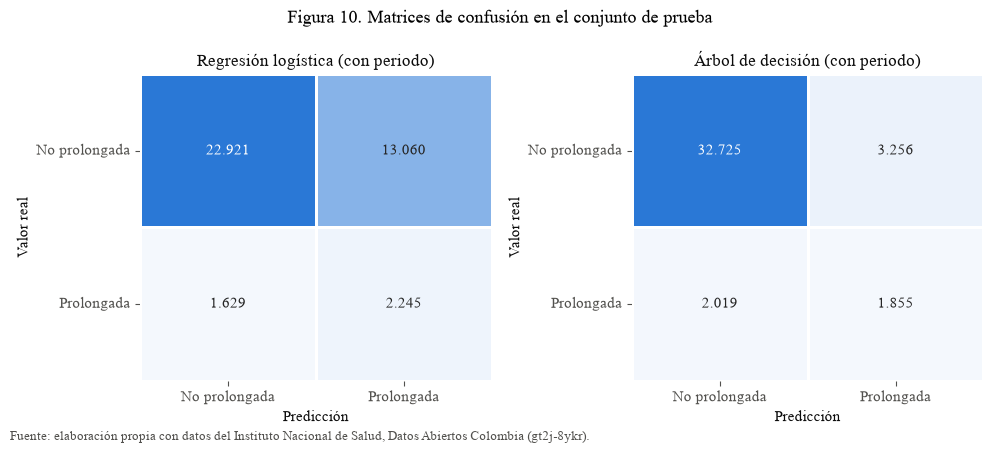

Figura guardada en: figuras/fig10_matrices_confusion.png


In [42]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.4))
mapa_azul = LinearSegmentedColormap.from_list('azules', ['#f4f8fd', AZUL])
for eje, nombre in zip(ejes, ['Regresión logística', 'Árbol de decisión']):
    modelo, cols = modelos[(nombre, 'con periodo')]
    mc = confusion_matrix(y_pru, modelo.predict(X_pru[cols]), labels=[0, 1])
    sns.heatmap(mc, annot=np.vectorize(miles)(mc), fmt='', cmap=mapa_azul, cbar=False, linewidths=2, linecolor='white',
                xticklabels=['No prolongada', 'Prolongada'], yticklabels=['No prolongada', 'Prolongada'], ax=eje)
    eje.set_title(f'{nombre} (con periodo)', fontsize=12)
    eje.set_xlabel('Predicción')
    eje.set_ylabel('Valor real')
    eje.tick_params(axis='y', rotation=0)
    eje.grid(False)
fig.suptitle('Figura 10. Matrices de confusión en el conjunto de prueba', fontsize=13)
fig.tight_layout()
guardar_figura(fig, 'fig10_matrices_confusion.png')

**Figura 10.** La regresión logística marca muchos casos como prolongados: acierta 2.245, pero se equivoca en 13.060. El árbol es más selectivo: acierta 1.855 y se equivoca en 3.256. Los dos dejan sin detectar una parte importante de los casos prolongados (1.629 y 2.019).

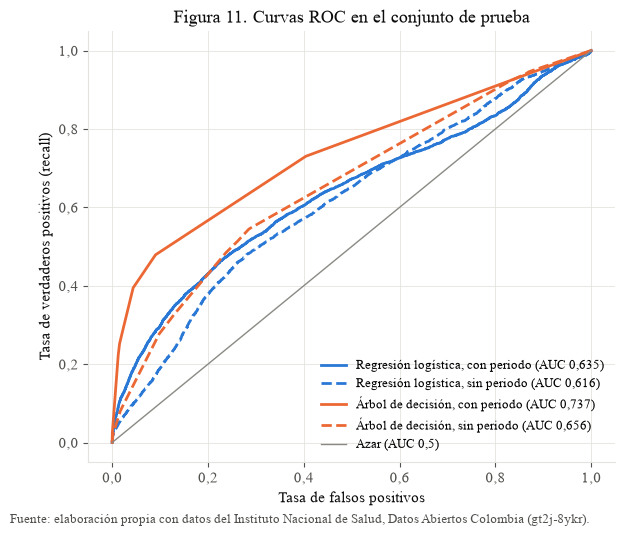

Figura guardada en: figuras/fig11_curvas_roc.png


In [43]:
fig, ax = plt.subplots(figsize=(6.8, 5.6))
estilos = {('Regresión logística', 'con periodo'): (AZUL, '-'), ('Regresión logística', 'sin periodo'): (AZUL, '--'),
           ('Árbol de decisión', 'con periodo'): (NARANJA, '-'), ('Árbol de decisión', 'sin periodo'): (NARANJA, '--')}
for clave, (modelo, cols) in modelos.items():
    prob = modelo.predict_proba(X_pru[cols])[:, 1]
    fpr, tpr, _ = roc_curve(y_pru, prob)
    color, linea = estilos[clave]
    auc = roc_auc_score(y_pru, prob)
    ax.plot(fpr, tpr, color=color, linestyle=linea, linewidth=2, label=f'{clave[0]}, {clave[1]} (AUC {decimal(auc, 3)})')
ax.plot([0, 1], [0, 1], color=GRIS, linewidth=1, label='Azar (AUC 0,5)')
ax.set_title('Figura 11. Curvas ROC en el conjunto de prueba')
ax.set_xlabel('Tasa de falsos positivos')
ax.set_ylabel('Tasa de verdaderos positivos (recall)')
ax.legend(loc='lower right', fontsize=9)
for eje_fmt in (ax.xaxis, ax.yaxis):
    eje_fmt.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: decimal(v, 1)))
guardar_figura(fig, 'fig11_curvas_roc.png')

**Figura 11.** La curva ROC muestra, para cada umbral de decisión, la proporción de casos prolongados detectados frente a la de falsos positivos. La curva del árbol con periodo (AUC de 0,737) está claramente por encima de las demás, que están cerca entre sí (0,616 a 0,656) y moderadamente por encima de la diagonal del azar.

### 8.9 Interpretación de los modelos

In [44]:
def coeficientes(conjunto):
    modelo, cols = modelos[('Regresión logística', conjunto)]
    nombres = modelo.named_steps['prep'].get_feature_names_out()
    nombres = [n.split('__', 1)[1] for n in nombres]
    coef = modelo.named_steps['clf'].coef_[0]
    return pd.Series(coef, index=nombres)

tabla_coef = pd.DataFrame({'coef_con_periodo': coeficientes('con periodo'), 'coef_sin_periodo': coeficientes('sin periodo')})
tabla_coef['razon_odds_con_periodo'] = np.exp(tabla_coef['coef_con_periodo'])
tabla_coef = tabla_coef.reindex(tabla_coef['coef_con_periodo'].abs().sort_values(ascending=False).index)
display(tabla_coef.round(3))
print('Las numéricas están escaladas: su coeficiente corresponde a aumentar una desviación estándar.')
print('Desviación estándar en entrenamiento: edad', round(X_ent['edad_anios'].std(), 2), 'años | meses desde inicio',
      round(X_ent['meses_desde_inicio'].std(), 2), '| días síntomas a diagnóstico', round(X_ent['dias_sintomas_a_diagnostico'].std(), 2))

,coef_con_periodo,coef_sin_periodo,razon_odds_con_periodo
asintomatico,2.289,2.659,9.861
contagio_relacionado,-0.571,-0.595,0.565
pertenencia_etnica_cod_1,0.401,0.649,1.493
dias_sintomas_a_diagnostico,-0.284,-0.332,0.753
meses_desde_inicio,-0.221,NaN,0.802
pertenencia_etnica_cod_5,-0.125,-0.063,0.883
edad_anios,0.109,0.097,1.115
es_cartagena,0.108,0.108,1.114
sexo_cod,0.107,0.133,1.112
contagio_importado,0.048,0.080,1.049


Las numéricas están escaladas: su coeficiente corresponde a aumentar una desviación estándar.
Desviación estándar en entrenamiento: edad 17.96 años | meses desde inicio 6.2 | días síntomas a diagnóstico 5.63


**Coeficientes de la regresión logística.** La razón de odds (*odds ratio*) es la exponencial del coeficiente: un valor mayor que 1 indica que la variable aumenta la probabilidad de recuperación prolongada, y uno menor que 1 que la disminuye. En el modelo con periodo:

- Ser **asintomático** tiene la razón más alta (9,861), pero son solo 669 casos y su fecha de inicio de síntomas está vacía por definición, así que el resultado debe tomarse con cautela.
- El **contagio relacionado** se asocia con menor probabilidad (0,565).
- La **población indígena** tiene una razón de 1,493 frente a la categoría "Otro", aunque con solo 1.930 casos.
- Un aumento de 5,63 días en los **días de síntomas a diagnóstico** (una desviación estándar) tiene una razón de 0,753, y uno de 6,2 **meses desde el inicio** una de 0,802.
- La **edad**, **Cartagena** y el **sexo masculino** tienen efectos pequeños (razones entre 1,11 y 1,12). Para la edad, eso corresponde a 17,96 años más.

Los coeficientes son parecidos con y sin periodo, lo que indica que las demás variables no dependen del periodo para mostrar su efecto.

In [45]:
importancias = {}
for conjunto in CONJUNTOS:
    modelo, cols = modelos[('Árbol de decisión', conjunto)]
    nombres = [n.split('__', 1)[1] for n in modelo.named_steps['prep'].get_feature_names_out()]
    importancias[conjunto] = pd.Series(modelo.named_steps['clf'].feature_importances_, index=nombres)
tabla_imp = pd.DataFrame(importancias).fillna(0).sort_values('con periodo', ascending=False)
display((tabla_imp * 100).round(1).rename(columns=lambda c: f'importancia_% {c}'))
arbol_sin, cols_sin = modelos[('Árbol de decisión', 'sin periodo')]
print('Profundidad del árbol sin periodo:', arbol_sin.named_steps['clf'].get_depth(),
      '| hojas:', arbol_sin.named_steps['clf'].get_n_leaves())
arbol_con, cols_con = modelos[('Árbol de decisión', 'con periodo')]
print('Profundidad del árbol con periodo:', arbol_con.named_steps['clf'].get_depth(),
      '| hojas:', arbol_con.named_steps['clf'].get_n_leaves())

,importancia_% con periodo,importancia_% sin periodo
meses_desde_inicio,94.6,0.0
dias_sintomas_a_diagnostico,5.4,72.7
asintomatico,0.0,11.7
contagio_importado,0.0,0.0
contagio_relacionado,0.0,11.5
edad_anios,0.0,0.6
es_cartagena,0.0,0.2
pertenencia_etnica_cod_1,0.0,0.0
pertenencia_etnica_cod_2,0.0,0.0
pertenencia_etnica_cod_5,0.0,3.4


Profundidad del árbol sin periodo: 4 | hojas: 16
Profundidad del árbol con periodo: 3 | hojas: 8


**Importancia de las variables en el árbol.** La importancia mide cuánto contribuye cada variable a separar las clases. En el árbol con periodo, `meses_desde_inicio` concentra el 94,6 % de la importancia y los días de síntomas a diagnóstico el 5,4 %; las demás variables no participan. Sin periodo, los días de síntomas a diagnóstico pasan al 72,7 %, seguidos de `asintomatico` (11,7 %) y del contagio relacionado (11,5 %). La edad apenas aporta (0,6 %).

In [46]:
for conjunto in CONJUNTOS:
    modelo, cols = modelos[('Árbol de decisión', conjunto)]
    nombres = [n.split('__', 1)[1] for n in modelo.named_steps['prep'].get_feature_names_out()]
    print(f'Reglas del árbol {conjunto} (class: 1 = prolongada):')
    print(export_text(modelo.named_steps['clf'], feature_names=nombres, decimals=1))

Reglas del árbol con periodo (class: 1 = prolongada):
|--- meses_desde_inicio <= 4.5
|   |--- dias_sintomas_a_diagnostico <= 10.5
|   |   |--- dias_sintomas_a_diagnostico <= 8.5
|   |   |   |--- class: 1
|   |   |--- dias_sintomas_a_diagnostico >  8.5
|   |   |   |--- class: 1
|   |--- dias_sintomas_a_diagnostico >  10.5
|   |   |--- meses_desde_inicio <= 2.5
|   |   |   |--- class: 1
|   |   |--- meses_desde_inicio >  2.5
|   |   |   |--- class: 1
|--- meses_desde_inicio >  4.5
|   |--- meses_desde_inicio <= 25.5
|   |   |--- meses_desde_inicio <= 13.5
|   |   |   |--- class: 0
|   |   |--- meses_desde_inicio >  13.5
|   |   |   |--- class: 0
|   |--- meses_desde_inicio >  25.5
|   |   |--- dias_sintomas_a_diagnostico <= 15.5
|   |   |   |--- class: 1
|   |   |--- dias_sintomas_a_diagnostico >  15.5
|   |   |   |--- class: 1

Reglas del árbol sin periodo (class: 1 = prolongada):
|--- dias_sintomas_a_diagnostico <= 13.5
|   |--- contagio_relacionado <= 0.5
|   |   |--- dias_sintomas_a_

**Reglas de los árboles.** El árbol con periodo es casi una regla de tiempo: marca como prolongados los casos diagnosticados hasta el mes 4 desde el inicio (marzo a julio de 2020) y desde el mes 26 (mayo de 2022 en adelante), y como no prolongados los del periodo intermedio. El árbol sin periodo separa primero los casos con 14 o 15 días de síntomas a diagnóstico, que son el valor amontonado de la figura 4, de los demás.

In [47]:
# Tasa de recuperación prolongada en los tramos que usan los árboles
tramo_periodo = pd.cut(pob['meses_desde_inicio'], bins=[-1, 4, 25, np.inf],
                       labels=['marzo a julio de 2020', 'agosto de 2020 a abril de 2022', 'mayo de 2022 en adelante'])
tramo_dias = pd.cut(pob['dias_sintomas_a_diagnostico'], bins=[-1, 13, 15, np.inf], labels=['0 a 13 días', '14 o 15 días', '16 días o más'])
for nombre, tramo in [('Periodo de diagnóstico', tramo_periodo), ('Días de síntomas a diagnóstico', tramo_dias)]:
    tabla = pob.groupby(tramo, observed=True)['recuperacion_prolongada'].agg(
        casos='size', pct_prolongada=lambda s: round(s.astype(float).mean() * 100, 2))
    print(nombre)
    print(tabla.to_string())
    print()
print('Asintomáticos (sin dato de días):', int(pob['asintomatico'].sum()))

Periodo de diagnóstico
                                 casos  pct_prolongada
meses_desde_inicio                                    
marzo a julio de 2020            19023           35.61
agosto de 2020 a abril de 2022  174179            5.82
mayo de 2022 en adelante          6072           40.61

Días de síntomas a diagnóstico
                              casos  pct_prolongada
dias_sintomas_a_diagnostico                        
0 a 13 días                   60185           15.53
14 o 15 días                 129856             6.4
16 días o más                  8564            15.9

Asintomáticos (sin dato de días): 669


La tabla confirma lo que hacen los árboles. Los casos diagnosticados entre marzo y julio de 2020 tuvieron recuperación prolongada en el 35,61 % de las veces, los de agosto de 2020 a abril de 2022 en el 5,82 % y los de mayo de 2022 en adelante en el 40,61 %. Los casos con 14 o 15 días de síntomas a diagnóstico, que son 129.856, tuvieron recuperación prolongada en el 6,4 %, frente al 15,53 % de los que tienen menos días y al 15,9 % de los que tienen más. Como 14 parece un valor por defecto de la fuente, los resultados sugieren que esa variable distingue sobre todo los registros con fechas completas de los registros con fechas por defecto, y no necesariamente una diferencia en la evolución de las personas.

### 8.10 Conclusiones del modelado supervisado

1. El mejor modelo es el árbol de decisión con periodo (F1 de 0,413, ROC-AUC de 0,737, lift de 3,73), pero casi todo su desempeño viene del momento del diagnóstico. Ese momento refleja tanto la evolución de la pandemia como los cambios en los protocolos de prueba y de cierre de casos, y con estos datos no podemos separar ambos efectos.
2. Sin el periodo, las características de las personas permiten un modelo apenas moderado (ROC-AUC entre 0,616 y 0,656). Los resultados sugieren que la recuperación prolongada se asocia algo más con los casos asintomáticos, con el contagio comunitario frente al relacionado, con la población indígena y, en menor grado, con la edad.
3. No hay sobreajuste, pero sí subajuste: faltan variables clínicas, como comorbilidades o vacunación, que la fuente no publica.
4. Por eso el modelo **no sirve para decidir sobre personas concretas**. Puede apoyar una planeación agregada, por ejemplo prever que en periodos de cambio de protocolo o de baja circulación los cierres registrados tienden a ser más largos, siempre con revisión humana.

## 9. Modelado no supervisado

En el aprendizaje no supervisado no hay variable objetivo: el algoritmo busca grupos de observaciones parecidas entre sí. Aquí agrupamos los 46 municipios (45 de Bolívar más Cartagena) según el comportamiento de sus casos, para identificar perfiles territoriales que orienten al CRT. Usamos **K-means**, que asigna cada municipio al grupo cuyo centro, el promedio de sus integrantes, le queda más cerca.

### 9.1 Variables del agrupamiento

Usamos las variables aprobadas en la ficha de trazabilidad (campo 17), calculadas en la sección 6.10. Para el número de casos usamos su logaritmo en base 10: los municipios van de 80 a 163.526 casos, y sin esa transformación Cartagena formaría un grupo por sí sola solo por su tamaño. Con el logaritmo, pasar de 100 a 1.000 casos pesa lo mismo que pasar de 1.000 a 10.000.

In [48]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

VARS_CLUSTER = ['log10_casos', 'edad_mediana', 'pct_60_o_mas', 'pct_hombres', 'pct_contagio_relacionado',
                'mediana_dias_sintomas_diagnostico', 'pct_fallecidos_covid', 'pct_recuperacion_prolongada']
mun = municipios.copy()
mun['log10_casos'] = np.log10(mun['casos'])
print('Municipios:', len(mun), '| variables para el agrupamiento:', len(VARS_CLUSTER))
print('Faltantes:', int(mun[VARS_CLUSTER].isna().sum().sum()))
display(mun[VARS_CLUSTER].describe().T.round(2))
print('Casos por municipio: mínimo', int(mun['casos'].min()), '| máximo', int(mun['casos'].max()),
      '| log10: de', round(mun['log10_casos'].min(), 2), 'a', round(mun['log10_casos'].max(), 2))

Municipios: 46 | variables para el agrupamiento: 8
Faltantes: 0


,count,mean,std,min,25%,50%,75%,max
log10_casos,46.0,2.666989,0.611407,1.90309,2.321694,2.519147,2.773711,5.213587
edad_mediana,46.0,39.543478,3.421868,34.0,37.25,39.0,41.0,54.0
pct_60_o_mas,46.0,19.643261,4.810702,12.57,16.94,19.38,21.7125,41.46
pct_hombres,46.0,45.382174,5.962873,32.5,42.2,44.105,47.4125,71.73
pct_contagio_relacionado,46.0,20.706522,8.309053,6.5,15.305,19.765,24.975,49.38
mediana_dias_sintomas_diagnostico,46.0,13.021739,2.175511,6.0,14.0,14.0,14.0,14.0
pct_fallecidos_covid,46.0,3.322174,2.23984,0.58,1.735,2.825,3.9575,12.2
pct_recuperacion_prolongada,46.0,10.08,6.854542,2.54,6.3575,8.505,11.48,43.84


Casos por municipio: mínimo 80 | máximo 163526 | log10: de 1.9 a 5.21


Las 8 variables no tienen faltantes. Hay mucha variación entre municipios: el porcentaje de recuperación prolongada va del 2,54 % al 43,84 % y el de fallecidos por COVID-19 del 0,58 % al 12,2 %. La mediana de días de síntomas a diagnóstico es 14 en la mayoría de los municipios (el primer cuartil, la mediana y el tercer cuartil valen 14), así que esta variable solo distingue a los pocos municipios donde el valor por defecto es menos frecuente.

In [49]:
corr_mun = mun[VARS_CLUSTER].corr().round(2)
display(corr_mun)
pares = corr_mun.where(np.triu(np.ones(corr_mun.shape, dtype=bool), k=1)).stack()
print('Pares con correlación absoluta mayor que 0,7:')
print(pares[pares.abs() > 0.7].to_string() if (pares.abs() > 0.7).any() else 'ninguno')

,log10_casos,edad_mediana,pct_60_o_mas,pct_hombres,pct_contagio_relacionado,mediana_dias_sintomas_diagnostico,pct_fallecidos_covid,pct_recuperacion_prolongada
log10_casos,1.00,-0.19,-0.28,-0.04,0.16,0.06,-0.42,-0.18
edad_mediana,-0.19,1.00,0.82,-0.05,-0.10,0.20,0.64,0.42
pct_60_o_mas,-0.28,0.82,1.00,-0.18,-0.00,0.21,0.65,0.40
pct_hombres,-0.04,-0.05,-0.18,1.00,-0.20,-0.16,-0.09,-0.02
pct_contagio_relacionado,0.16,-0.10,-0.00,-0.20,1.00,0.09,-0.33,-0.32
mediana_dias_sintomas_diagnostico,0.06,0.20,0.21,-0.16,0.09,1.00,-0.11,-0.13
pct_fallecidos_covid,-0.42,0.64,0.65,-0.09,-0.33,-0.11,1.00,0.60
pct_recuperacion_prolongada,-0.18,0.42,0.40,-0.02,-0.32,-0.13,0.60,1.00


Pares con correlación absoluta mayor que 0,7:
edad_mediana  pct_60_o_mas    0.82


La edad mediana y el porcentaje de casos de 60 años o más tienen una correlación de 0,82, el único par por encima de 0,7. Las dos miden la edad de los casos, así que en la práctica la edad pesa algo más en el agrupamiento. Las conservamos porque fueron aprobadas en la ficha y porque una mide el centro de la distribución y la otra la proporción de personas mayores. El porcentaje de fallecidos se relaciona con la edad (0,64 y 0,65) y con la recuperación prolongada (0,60).

### 9.2 Escalamiento

K-means usa distancias, así que una variable con valores grandes, como un porcentaje, pesaría más que una con valores pequeños, como el logaritmo de los casos. Por eso escalamos todas las variables para que tengan media 0 y desviación estándar 1.

In [50]:
escalador_mun = StandardScaler()
Z = escalador_mun.fit_transform(mun[VARS_CLUSTER])
print('Media de cada variable escalada:', np.round(Z.mean(axis=0), 6).tolist())
print('Desviación estándar de cada variable escalada:', np.round(Z.std(axis=0), 6).tolist())

Media de cada variable escalada: [0.0, 0.0, -0.0, 0.0, 0.0, -0.0, -0.0, 0.0]
Desviación estándar de cada variable escalada: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


### 9.3 Elección del número de grupos

Probamos de 2 a 8 grupos. Para cada valor de *k* calculamos dos medidas:

- **Inercia:** la suma de las distancias al cuadrado de cada municipio al centro de su grupo. Siempre baja al aumentar *k*; el **método del codo** busca el punto a partir del cual agregar grupos ya no la reduce mucho.
- **Coeficiente de silueta:** compara, para cada municipio, qué tan cerca está de su propio grupo frente al grupo vecino. Va de −1 a 1; valores más altos indican grupos mejor separados.

También revisamos el tamaño del grupo más pequeño, porque un grupo de un solo municipio no describe un perfil. Usamos 50 inicializaciones distintas por cada *k* y una semilla fija para que el resultado sea estable.

In [51]:
K_VALORES = range(2, 9)
evaluacion_k = []
for k in K_VALORES:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEMILLA).fit(Z)
    tamanos = np.bincount(km.labels_)
    evaluacion_k.append({'k': k, 'inercia': km.inertia_, 'silhouette': silhouette_score(Z, km.labels_),
                         'grupo_mas_pequeno': int(tamanos.min()), 'tamanos': sorted(tamanos.tolist(), reverse=True)})
evaluacion_k = pd.DataFrame(evaluacion_k).set_index('k')
evaluacion_k['caida_inercia_pct'] = (-evaluacion_k['inercia'].pct_change() * 100).round(1)
display(evaluacion_k.round(3))

,inercia,silhouette,grupo_mas_pequeno,tamanos,caida_inercia_pct
k,,,,,
2,273.716,0.467,4,"[42, 4]",NaN
3,223.286,0.390,4,"[38, 4, 4]",18.4
4,192.846,0.181,4,"[24, 14, 4, 4]",13.6
5,168.348,0.195,4,"[22, 12, 4, 4, 4]",12.7
6,145.395,0.173,1,"[17, 17, 4, 4, 3, 1]",13.6
7,123.505,0.204,1,"[21, 11, 4, 4, 4, 1, 1]",15.1
8,105.831,0.210,1,"[19, 10, 4, 4, 4, 3, 1, 1]",14.3


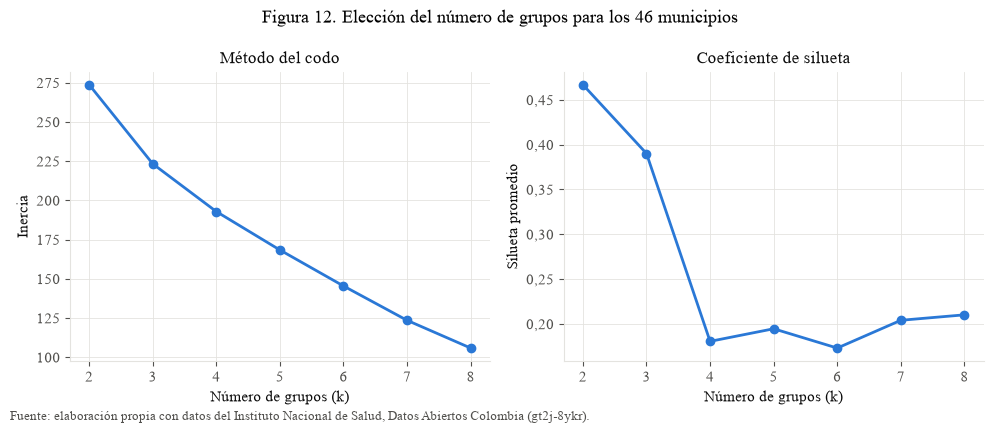

Figura guardada en: figuras/fig12_eleccion_k.png


In [52]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
ax1.plot(evaluacion_k.index, evaluacion_k['inercia'], color=AZUL, linewidth=2, marker='o', markersize=6)
ax1.set_title('Método del codo', fontsize=12)
ax1.set_xlabel('Número de grupos (k)')
ax1.set_ylabel('Inercia')
ax2.plot(evaluacion_k.index, evaluacion_k['silhouette'], color=AZUL, linewidth=2, marker='o', markersize=6)
ax2.set_title('Coeficiente de silueta', fontsize=12)
ax2.set_xlabel('Número de grupos (k)')
ax2.set_ylabel('Silueta promedio')
for eje in (ax1, ax2):
    eje.set_xticks(list(evaluacion_k.index))
ax1.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: decimal(v, 0)))
ax2.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: decimal(v, 2)))
fig.suptitle('Figura 12. Elección del número de grupos para los 46 municipios', fontsize=13)
fig.tight_layout()
guardar_figura(fig, 'fig12_eleccion_k.png')

La silueta más alta es la de *k* = 2 (0,467), seguida de *k* = 3 (0,390); desde *k* = 4 baja a valores entre 0,173 y 0,210, que indican grupos poco separados. La inercia no muestra un codo marcado: cada grupo adicional la reduce entre el 12,7 % y el 18,4 %, y la mayor caída es al pasar de 2 a 3 grupos. Desde *k* = 6 aparecen grupos de un solo municipio. La elección de *k* se justifica en la sección siguiente.

### 9.4 Modelo final con *k* = 3

Elegimos 3 grupos. La silueta de *k* = 3 es la segunda más alta y sigue siendo aceptable. La caída de la inercia al pasar de 2 a 3 grupos es la mayor de todas. Además, el tercer grupo agrega un perfil interpretable que *k* = 2 no muestra, mientras que desde *k* = 4 los grupos casi no se distinguen. Nombramos los grupos con una regla aplicada a sus centros, no por el número que asigna K-means. También comprobamos si la partición cambia con otras semillas usando el índice de Rand ajustado, que vale 1 cuando dos agrupamientos son idénticos.

In [53]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

K_ELEGIDO = 3
kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=50, random_state=SEMILLA).fit(Z)
etiquetas = pd.Series(kmeans.labels_, index=mun.index)

# Nombres asignados por regla a partir de los centros, no por el número que da K-means
centros = pd.DataFrame(escalador_mun.inverse_transform(kmeans.cluster_centers_), columns=VARS_CLUSTER)
g_prolongada = int(centros['pct_recuperacion_prolongada'].idxmax())
g_registro = int(centros.drop(index=g_prolongada)['mediana_dias_sintomas_diagnostico'].idxmin())
g_mayoritario = ({0, 1, 2} - {g_prolongada, g_registro}).pop()
NOMBRES_GRUPO = {g_mayoritario: 'A. Perfil mayoritario',
                 g_prolongada: 'B. Mayor edad y recuperaciones más largas',
                 g_registro: 'C. Menor uso del valor de 14 días'}
mun['grupo'] = etiquetas.map(NOMBRES_GRUPO)
print('Silueta con k = 3:', round(silhouette_score(Z, kmeans.labels_), 3))
print('Tamaño de los grupos:')
print(mun['grupo'].value_counts().sort_index().to_string())

# Estabilidad: ¿la partición cambia con otras semillas?
ari = [adjusted_rand_score(kmeans.labels_, KMeans(n_clusters=K_ELEGIDO, n_init=50, random_state=s).fit_predict(Z))
       for s in range(10)]
print('Índice de Rand ajustado frente a 10 semillas distintas: mínimo', round(min(ari), 3), '| máximo', round(max(ari), 3))

Silueta con k = 3: 0.39
Tamaño de los grupos:
grupo
A. Perfil mayoritario                        38
B. Mayor edad y recuperaciones más largas     4
C. Menor uso del valor de 14 días             4
Índice de Rand ajustado frente a 10 semillas distintas: mínimo 1.0 | máximo 1.0


El modelo final tiene una silueta de 0,39. El grupo A reúne 38 municipios y los grupos B y C 4 cada uno. Con 10 semillas distintas, el índice de Rand ajustado es 1 en todos los casos: la partición es la misma, así que no depende del punto de inicio del algoritmo.

### 9.5 Tamaño y perfil promedio de cada grupo

Para cada grupo calculamos el promedio de cada indicador entre sus municipios. También calculamos una tasa agregada de recuperación prolongada: los casos prolongados del grupo divididos por todos sus recuperados, sin promediar municipios. Así los municipios grandes pesan según su número de casos.

In [54]:
perfiles = mun.groupby('grupo').agg(
    municipios=('municipio_nom', 'size'),
    casos_totales=('casos', 'sum'),
    municipios_menos_100_casos=('menos_de_100_casos', 'sum'),
    **{f'media_{v}': (v, 'mean') for v in VARS_CLUSTER if v != 'log10_casos'},
)
# Tasa agregada exacta: se cruza cada caso de la población supervisada con el grupo de su municipio
grupo_por_municipio = mun.set_index('municipio_cod_divipola')['grupo']
perfiles['pct_prolongada_agregada'] = (pob.assign(grupo=pob['municipio_cod_divipola'].map(grupo_por_municipio))
                                       .groupby('grupo')['recuperacion_prolongada'].apply(lambda s: s.astype(float).mean() * 100))
display(perfiles.astype(float).T.round(2))
print('pct_prolongada_agregada: casos prolongados del grupo sobre sus recuperados, sin promediar municipios.')
print()
for nombre, d in mun.sort_values('casos', ascending=False).groupby('grupo'):
    print(f'{nombre} ({len(d)}):', ', '.join(d['municipio_nom']))

grupo,A. Perfil mayoritario,B. Mayor edad y recuperaciones más largas,C. Menor uso del valor de 14 días
municipios,38.00,4.00,4.00
casos_totales,200736.00,517.00,2609.00
municipios_menos_100_casos,1.00,2.00,0.00
media_edad_mediana,39.05,46.25,37.50
media_pct_60_o_mas,19.17,29.49,14.26
media_pct_hombres,44.72,43.94,53.13
media_pct_contagio_relacionado,22.59,10.68,12.82
media_mediana_dias_sintomas_diagnostico,13.63,13.00,7.25
media_pct_fallecidos_covid,2.72,8.70,3.64
media_pct_recuperacion_prolongada,8.35,25.09,11.47


pct_prolongada_agregada: casos prolongados del grupo sobre sus recuperados, sin promediar municipios.

A. Perfil mayoritario (38): Cartagena, Magangue, Turbaco, Arjona, El Carmen De Bolivar, Mompos, San Juan Nepomuceno, Maria La Baja, San Jacinto, Pinillos, Simiti, Villanueva, Cicuco, Santa Rosa, Cordoba, Calamar, Mahates, Turbana, Achi, Zambrano, San Cristobal, Talaigua Nuevo, El Guamo, Barranco De Loba, Tiquisio (Puerto Rico), San Estanislao, Santa Catalina, Rio Viejo, Altos Del Rosario, Margarita, Arenal, Soplaviento, Norosì, El Peñon, Hatillo De Loba, Regidor, Montecristo, Arroyohondo
B. Mayor edad y recuperaciones más largas (4): San Martin De Loba, Morales, San Fernando, San Jacinto Del Cauca
C. Menor uso del valor de 14 días (4): Santa Rosa Del Sur, San Pablo, Clemencia, Cantagallo


- **Grupo A, perfil mayoritario (38 municipios, 200.736 casos).** Incluye a Cartagena, Magangué, Turbaco y Arjona, así que concentra casi todos los casos del territorio. En promedio, la edad mediana es de 39,05 años, el 2,72 % de los casos falleció por COVID-19 y el 8,35 % de los recuperados tuvo recuperación prolongada; la tasa agregada es de 9,69 %. Tiene la mayor proporción de contagios relacionados (22,59 %). Solo uno de sus municipios, Arroyohondo, tiene menos de 100 casos.
- **Grupo B, mayor edad y recuperaciones más largas (4 municipios, 517 casos).** San Martín de Loba, Morales, San Fernando y San Jacinto del Cauca. Sus casos son mayores (edad mediana promedio de 46,25 años y 29,49 % de 60 años o más), con más fallecidos por COVID-19 (8,7 % en promedio) y más recuperación prolongada (25,09 % en promedio y 22,32 % agregada, más del doble que el grupo A). Dos de sus municipios tienen menos de 100 casos, así que sus porcentajes son poco estables.
- **Grupo C, menor uso del valor de 14 días (4 municipios, 2.609 casos).** Santa Rosa del Sur, San Pablo, Clemencia y Cantagallo. Se distinguen porque la mediana de días de síntomas a diagnóstico es de 7,25 en promedio, frente a 13,63 en el grupo A, es decir, usan mucho menos el valor de 14 días que parece un valor por defecto de la fuente. También tienen más hombres (53,13 %) y menos contagios relacionados (12,82 %). Su recuperación prolongada agregada (9,98 %) es casi igual a la del grupo A (9,69 %).

### 9.6 Visualización de los grupos

Con 8 variables no se pueden dibujar los municipios directamente. Usamos el **análisis de componentes principales** (PCA), que resume las variables en unas pocas combinaciones, llamadas componentes, que conservan la mayor parte de la variación. Dibujamos los municipios en las dos primeras.

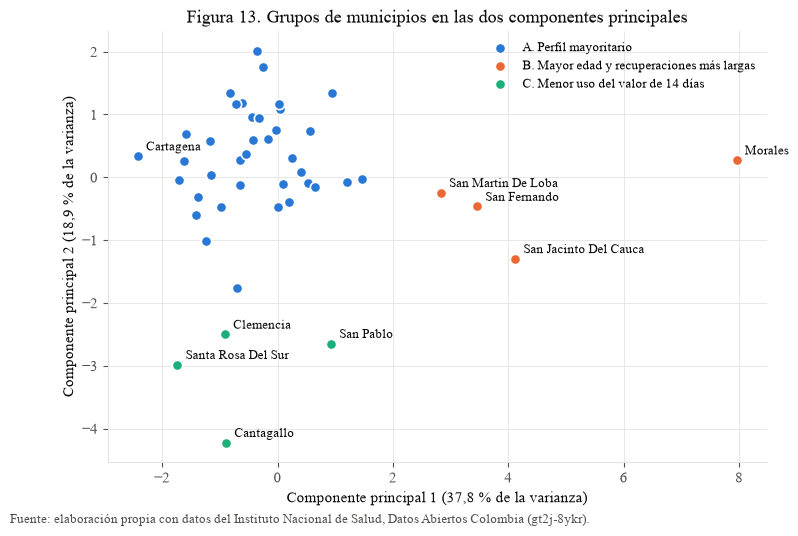

Figura guardada en: figuras/fig13_grupos_municipios_pca.png
Varianza explicada: componente 1 37.8 % | componente 2 18.9 % | total 56.7 %


,CP1,CP2
log10_casos,-0.27,0.19
edad_mediana,0.48,0.22
pct_60_o_mas,0.48,0.30
pct_hombres,-0.06,-0.47
pct_contagio_relacionado,-0.18,0.50
mediana_dias_sintomas_diagnostico,0.03,0.54
pct_fallecidos_covid,0.51,-0.12
pct_recuperacion_prolongada,0.40,-0.22


In [55]:
pca = PCA(n_components=2, random_state=SEMILLA)
P = pca.fit_transform(Z)
var_exp = pca.explained_variance_ratio_ * 100
COLORES_GRUPO = {'A. Perfil mayoritario': AZUL, 'B. Mayor edad y recuperaciones más largas': NARANJA,
                 'C. Menor uso del valor de 14 días': '#1baf7a'}
fig, ax = plt.subplots(figsize=(8.5, 5.6))
for nombre, color in COLORES_GRUPO.items():
    m = (mun['grupo'] == nombre).values
    ax.scatter(P[m, 0], P[m, 1], s=55, color=color, edgecolor='white', linewidth=1.2, label=nombre)
for i, fila in mun.reset_index(drop=True).iterrows():
    if fila['grupo'] != 'A. Perfil mayoritario' or fila['municipio_nom'] == 'Cartagena':
        ax.annotate(fila['municipio_nom'], xy=(P[i, 0], P[i, 1]), xytext=(6, 4), textcoords='offset points', fontsize=9, color=TEXTO)
ax.set_title('Figura 13. Grupos de municipios en las dos componentes principales')
ax.set_xlabel(f'Componente principal 1 ({decimal(var_exp[0])} % de la varianza)')
ax.set_ylabel(f'Componente principal 2 ({decimal(var_exp[1])} % de la varianza)')
ax.legend(loc='best', fontsize=9)
guardar_figura(fig, 'fig13_grupos_municipios_pca.png')
print('Varianza explicada: componente 1', round(var_exp[0], 1), '% | componente 2', round(var_exp[1], 1), '% | total', round(var_exp.sum(), 1), '%')
cargas = pd.DataFrame(pca.components_.T, index=VARS_CLUSTER, columns=['CP1', 'CP2']).round(2)
display(cargas)

**Figura 13.** Las dos primeras componentes conservan el 56,7 % de la variación de los datos (37,8 % y 18,9 %). La primera componente combina la edad (cargas de 0,48 en edad mediana y en porcentaje de 60 años o más), los fallecidos (0,51) y la recuperación prolongada (0,40); hacia la derecha están los municipios con casos mayores y desenlaces más desfavorables. Allí aparece el grupo B, con Morales muy separado del resto. La segunda componente combina la mediana de días de síntomas a diagnóstico (0,54), el contagio relacionado (0,50) y, en sentido contrario, el porcentaje de hombres (−0,47); hacia abajo está el grupo C. El grupo A forma una nube compacta en la que se encuentra Cartagena.

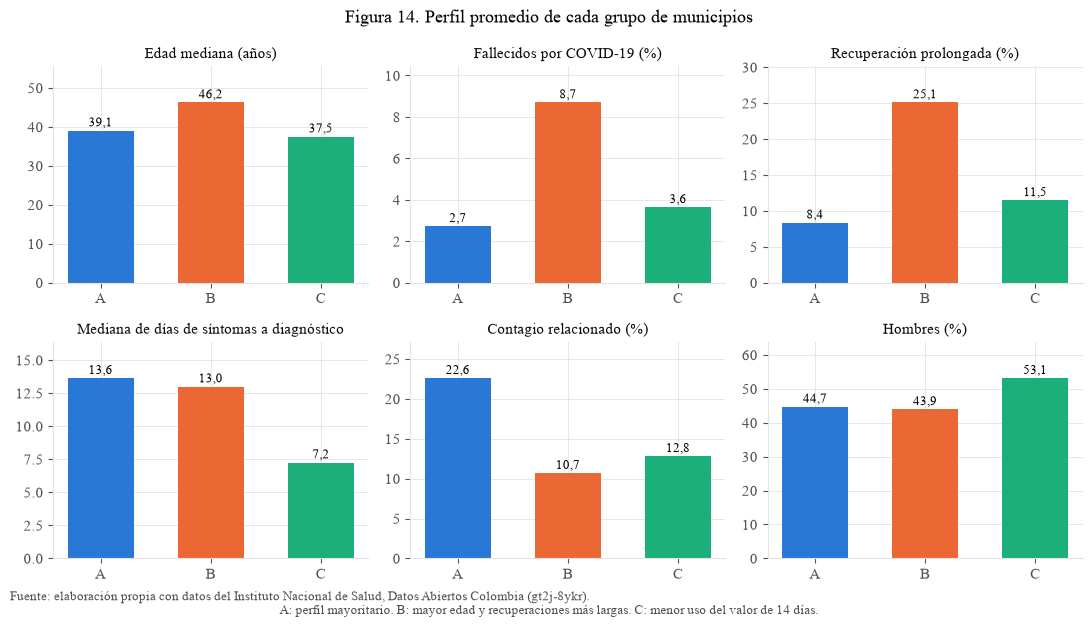

Figura guardada en: figuras/fig14_perfiles_grupos.png


In [56]:
INDICADORES = [('edad_mediana', 'Edad mediana (años)'), ('pct_fallecidos_covid', 'Fallecidos por COVID-19 (%)'),
               ('pct_recuperacion_prolongada', 'Recuperación prolongada (%)'),
               ('mediana_dias_sintomas_diagnostico', 'Mediana de días de síntomas a diagnóstico'),
               ('pct_contagio_relacionado', 'Contagio relacionado (%)'), ('pct_hombres', 'Hombres (%)')]
fig, ejes = plt.subplots(2, 3, figsize=(11, 6.2))
orden = list(COLORES_GRUPO)
for eje, (var, titulo) in zip(ejes.ravel(), INDICADORES):
    valores = perfiles.loc[orden, f'media_{var}']
    eje.bar(range(3), valores, color=[COLORES_GRUPO[g] for g in orden], width=0.6)
    for x, v in enumerate(valores):
        eje.annotate(decimal(v), xy=(x, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9)
    eje.set_title(titulo, fontsize=10.5)
    eje.set_xticks(range(3), ['A', 'B', 'C'])
    eje.set_ylim(0, valores.max() * 1.2)
fig.suptitle('Figura 14. Perfil promedio de cada grupo de municipios', fontsize=13)
fig.text(0.5, 0.005, 'A: perfil mayoritario. B: mayor edad y recuperaciones más largas. C: menor uso del valor de 14 días.',
         ha='center', fontsize=9.5, color=TEXTO_SEC)
fig.tight_layout(rect=(0, 0.03, 1, 1))
guardar_figura(fig, 'fig14_perfiles_grupos.png')

**Figura 14.** La comparación de perfiles confirma lo anterior. El grupo B se distingue en edad mediana, fallecidos y recuperación prolongada. El grupo C se distingue en la mediana de días de síntomas a diagnóstico y en el porcentaje de hombres, pero su recuperación prolongada promedio (11,5 %) está más cerca de la del grupo A (8,4 %) que de la del B (25,1 %).

### 9.7 Interpretación y limitaciones del agrupamiento

1. **El territorio es bastante homogéneo.** 38 de los 46 municipios, con casi todos los casos, comparten un perfil parecido. Las diferencias aparecen en pocos municipios pequeños.
2. **El grupo B es el perfil de atención prioritaria.** Sus casos son mayores y tuvieron más fallecimientos y recuperaciones más largas. Esto es coherente con el gradiente por edad de la sección 7 y con la correlación de 0,418 entre edad mediana y recuperación prolongada de la figura 9. Sin embargo, son solo 517 casos en total y dos municipios tienen menos de 100, así que el perfil debe confirmarse con más datos antes de tomar decisiones.
3. **El grupo C parece reflejar una diferencia de registro.** Lo que más lo separa es el uso de fechas de inicio de síntomas distintas al valor por defecto. Su recuperación prolongada no es muy distinta de la del grupo A, así que no lo interpretamos como un grupo con peor evolución.
4. **Los perfiles describen municipios, no personas.** Que un municipio pertenezca al grupo B no significa que cada persona de ese municipio tenga más riesgo; atribuir a los individuos una característica del grupo es la llamada falacia ecológica, y la evitamos.
5. **Limitaciones técnicas.** La muestra es pequeña (46 municipios), la edad pesa algo más por estar representada con dos variables correlacionadas, y la variable de días de síntomas a diagnóstico mide en parte la calidad del registro.

## 10. Integración, conclusiones técnicas y recomendaciones

Esta sección reúne los resultados del análisis exploratorio, del modelo supervisado y del agrupamiento, responde la pregunta de análisis y formula recomendaciones para el Centro Tutorial CRT. La tabla siguiente recoge las cifras clave, calculadas a partir de los resultados de las secciones anteriores.

In [57]:
# Cifras clave del proyecto, tomadas de los objetos calculados en las secciones anteriores
mejor = tabla_metricas.loc['Árbol de decisión (con periodo)']
sin_periodo = tabla_metricas.loc['Árbol de decisión (sin periodo)']
resumen_final = pd.DataFrame([
    ('Casos analizados', f'{len(casos):,}'.replace(',', '.')),
    ('Población supervisada (recuperados con días calculables)', f'{len(pob):,}'.replace(',', '.')),
    ('Recuperación prolongada (más de 21 días)', f"{y.mean() * 100:.2f} %"),
    ('Percentil 90 de días de diagnóstico a recuperación', f"{pob['dias_diagnostico_a_recuperacion'].quantile(0.9):.0f} días"),
    ('Prolongada en 0 a 17 años / 70 o más', f"{por_edad.loc['0 a 17', 'pct_prolongada']:.2f} % / {por_edad.loc['70 o más', 'pct_prolongada']:.2f} %"),
    ('Prolongada en cierres por PCR / por tiempo', f"{global_cierre.loc['PCR', 'pct_prolongada']:.2f} % / {global_cierre.loc['Tiempo', 'pct_prolongada']:.2f} %"),
    ('Mejor modelo: árbol con periodo (F1 / ROC-AUC / lift)', f"{mejor['f1']:.3f} / {mejor['roc_auc']:.3f} / {mejor['lift']:.2f}"),
    ('Árbol sin periodo (F1 / ROC-AUC)', f"{sin_periodo['f1']:.3f} / {sin_periodo['roc_auc']:.3f}"),
    ('Importancia del periodo en el mejor árbol', f"{tabla_imp.loc['meses_desde_inicio', 'con periodo'] * 100:.1f} %"),
    ('Grupos de municipios (A / B / C)', ' / '.join(str(int(perfiles.loc[g, 'municipios'])) for g in COLORES_GRUPO)),
    ('Prolongada agregada por grupo (A / B / C)', ' / '.join(f"{perfiles.loc[g, 'pct_prolongada_agregada']:.2f} %" for g in COLORES_GRUPO)),
    ('Casos del grupo B', f"{int(perfiles.loc['B. Mayor edad y recuperaciones más largas', 'casos_totales'])}"),
], columns=['indicador', 'valor'])
display(resumen_final)

,indicador,valor
0,Casos analizados,203.862
1,Población supervisada (recuperados con días ca...,199.274
2,Recuperación prolongada (más de 21 días),9.72 %
3,Percentil 90 de días de diagnóstico a recupera...,21 días
4,Prolongada en 0 a 17 años / 70 o más,8.51 % / 12.09 %
5,Prolongada en cierres por PCR / por tiempo,19.50 % / 7.41 %
6,Mejor modelo: árbol con periodo (F1 / ROC-AUC ...,0.413 / 0.737 / 3.73
7,Árbol sin periodo (F1 / ROC-AUC),0.260 / 0.656
8,Importancia del periodo en el mejor árbol,94.6 %
9,Grupos de municipios (A / B / C),38 / 4 / 4


### 10.1 Integración de hallazgos

Las tres fases del análisis apuntan en la misma dirección.

1. **El momento del diagnóstico es lo que más se asocia con una recuperación prolongada.** En el análisis exploratorio la tasa pasó de más del 40 % en algunos trimestres a menos del 4 % en otros (figura 6). En el modelo supervisado, el periodo concentra el 94,6 % de la importancia del mejor árbol, y al quitarlo el F1 baja de 0,413 a 0,260. Parte de este efecto viene del registro: los casos cerrados por PCR fueron prolongados en el 19,5 % de las veces y los cerrados por tiempo en el 7,41 % (figura 7).
2. **La edad tiene un efecto consistente pero moderado.** La recuperación prolongada sube del 8,51 % en menores de 18 años al 12,09 % en las personas de 70 años o más (figura 5). En el agrupamiento, los municipios del grupo B, con casos de mayor edad, tienen la tasa agregada más alta (22,32 %).
3. **Otras características individuales aportan poco.** El contagio relacionado se asocia con menos recuperación prolongada que el comunitario, y la población indígena con algo más, pero con pocos casos. El sexo y vivir en Cartagena tienen efectos muy pequeños.
4. **La calidad del registro deja huella en los resultados.** El valor de 14 días de síntomas a diagnóstico, que parece un valor por defecto, aparece como señal tanto en el árbol sin periodo como en el grupo C del agrupamiento.
5. **El territorio es bastante homogéneo.** 38 de los 46 municipios, con casi todos los casos, comparten un perfil parecido; solo 4 municipios pequeños (grupo B) se separan por tener casos mayores y más recuperaciones largas.

### 10.2 Respuesta a la pregunta de análisis

La pregunta era: *¿qué características conocidas el día del diagnóstico se asocian con una recuperación prolongada en los casos de COVID-19 de Bolívar y Cartagena entre 2020 y 2024, y qué perfiles de municipios pueden identificarse a partir del comportamiento de sus casos?*

**Respuesta.** Con los datos disponibles, los resultados sugieren que la característica más asociada con una recuperación prolongada es el periodo del diagnóstico: fue más frecuente al comienzo de la pandemia (marzo a julio de 2020) y desde mayo de 2022. Esta asociación mezcla la evolución de la pandemia con los cambios en la forma de confirmar la recuperación, y estos datos no permiten separar ambos efectos. Entre las características de las personas, la edad muestra la relación más consistente, aunque moderada, y el contagio relacionado se asocia con recuperaciones más cortas. Ningún modelo basado en estas variables permite anticipar con precisión qué persona tendrá una recuperación prolongada.

En cuanto a los municipios, identificamos tres perfiles: un perfil mayoritario de 38 municipios, entre ellos Cartagena; un perfil de 4 municipios pequeños con casos de mayor edad, más fallecimientos y más del doble de recuperación prolongada; y un perfil de 4 municipios que se distingue sobre todo por cómo registró las fechas de inicio de síntomas.

### 10.3 Recomendaciones para el Centro Tutorial CRT

Las recomendaciones se derivan de los resultados y se limitan a lo que los datos permiten. Ninguna se refiere a estudiantes concretos, porque los datos describen a la población del territorio.

1. **Prever plazos de flexibilidad de al menos tres semanas.** El 90 % de las recuperaciones registradas tomó 21 días o menos, pero cerca de 1 de cada 10 tomó más. Si el CRT define plazos de reintegro o de entrega ante una enfermedad respiratoria, conviene que cubran al menos tres semanas y que exista una vía para extenderlos.
2. **Dar prioridad a las personas mayores en la comunicación preventiva.** La recuperación prolongada aumentó con la edad. Los mensajes preventivos y de acompañamiento del CRT pueden hacer énfasis en la comunidad de 60 años o más.
3. **Tomar los municipios del grupo B como una señal por confirmar.** San Martín de Loba, Morales, San Fernando y San Jacinto del Cauca mostraron casos de mayor edad y más recuperaciones largas. Si el CRT atiende estudiantes de esos municipios, conviene revisar con ellos sus necesidades de acompañamiento. Por el bajo número de casos, no recomendamos asignar recursos solo con base en este resultado.
4. **Esperar recuperaciones registradas más largas en los primeros meses de una nueva emergencia.** El inicio de la pandemia coincidió con las recuperaciones más largas. Ante una situación similar, el CRT puede planear una flexibilidad mayor en las primeras semanas, mientras se estabilizan los protocolos.
5. **Usar los modelos solo para planeación agregada.** El modelo supervisado no debe usarse para clasificar a personas ni para decidir sobre su situación académica. Su valor está en mostrar qué factores y periodos merecen atención.
6. **Recolectar datos propios si se necesita un análisis de la comunidad del CRT.** Para conocer el efecto real en los estudiantes harían falta datos del CRT, como municipios de residencia y ausencias por enfermedad, recogidos con consentimiento y anonimizados.

### 10.4 Consideraciones éticas y de privacidad

- **Datos sensibles.** El dataset contiene información de salud, edad, sexo y pertenencia étnica. Trabajamos solo con datos anonimizados por el INS, retiramos el identificador del caso y dos fechas administrativas (principio de minimización) y no intentamos identificar a ninguna persona.
- **Resultados agregados.** Reportamos porcentajes y promedios de grupos, nunca casos individuales. En los municipios con pocos casos evitamos describir situaciones particulares.
- **Riesgo de estigmatización.** Los resultados por pertenencia étnica (población indígena) y por municipio (grupo B) se basan en pocos casos y no deben usarse para señalar comunidades ni para restringir oportunidades.
- **Falacia ecológica.** Los perfiles describen municipios. Atribuirlos a las personas que viven en ellos sería un error.
- **Uso no clínico.** Los resultados no son diagnósticos ni sustituyen el criterio médico, y no deben automatizar decisiones sobre personas.
- **Licencia.** Usamos y redistribuimos los datos bajo la licencia Creative Commons Atribución-CompartirIgual 4.0, citando al INS y compartiendo los archivos derivados con la misma licencia.

### 10.5 Sesgos y limitaciones

- **Selección:** solo incluye personas que se hicieron una prueba y fueron notificadas; los casos sin prueba quedan por fuera.
- **Cobertura:** Cartagena concentra el 80,21 % de los casos, así que los resultados globales reflejan sobre todo al distrito.
- **Medición de la variable objetivo:** la duración de la recuperación depende del tipo de cierre (PCR o tiempo) y de los protocolos de cada periodo.
- **Calidad de las predictoras:** el 51,65 % de los días de síntomas a diagnóstico vale 14, lo que sugiere un valor por defecto; la pertenencia étnica depende del autorreconocimiento.
- **Variables ausentes:** la fuente no publica comorbilidades, vacunación ni gravedad clínica detallada, por eso los modelos muestran subajuste.
- **Sin denominadores de población:** no calculamos tasas por habitante porque la fuente no incluye la población de cada municipio.
- **Tamaño de los grupos:** el agrupamiento usa 46 unidades y el grupo B tiene 517 casos, con dos municipios de menos de 100.
- **Actualidad:** los datos no se actualizan desde enero de 2024.
- **Alcance:** los datos describen a la población del territorio, no a los estudiantes del CRT.

### 10.6 Conclusiones técnicas

1. Preparamos un dataset verificable y reproducible: el archivo de partida coincide celda por celda con una descarga nueva de la fuente, y el notebook lo descarga solo si falta.
2. Corregimos un error heredado de la Actividad 2: el valor "N/A" de la fuente, que identifica a los fallecidos por otras causas, se leía como vacío. Corregirlo cambió la población del modelo de 199.129 a 199.274 casos.
3. El mejor modelo supervisado (árbol de decisión con periodo) supera ampliamente a la línea base (F1 de 0,413 frente a 0, ROC-AUC de 0,737 frente a 0,5), pero depende casi por completo del periodo. Sin él, el desempeño es moderado (ROC-AUC de 0,656).
4. El agrupamiento con *k* = 3 es estable y muestra un territorio homogéneo con un pequeño perfil de mayor edad y recuperaciones más largas.
5. Los resultados sirven para una planeación agregada y prudente del CRT, no para decisiones individuales. Para avanzar harían falta variables clínicas y datos propios de la comunidad del CRT.